# Time Series Analysis

Weeks 1 and 2 treated each day as one observation among many and asked how a return relates to other variables on the same day. This notebook treats returns as a sequence and asks what the past says about the future:

1. Time Series and Stationarity
2. Autocorrelation
3. AR, MA and ARMA Models
4. ARIMA and Model Building
5. Forecasting
6. Volatility and GARCH

The notebook contains three kinds of cells:

- **Provided code**: complete code. Run it as it is.
- **Task**: a description of what to compute or plot, followed by an empty code cell. Write the code yourself; add more cells if needed. Each Task gives reference values so you can check your implementation.
- **Question**: a written question. Answer it in prose in the **Answer** cell (a markdown cell) below it, using the numbers from your own results.

Save this notebook and `week3_data.csv` in the same folder before running it; the Setup cell reads `week3_data.csv` from that folder.

Run the cells from top to bottom. Later sections use variables created earlier.

Be prepared to explain everything you write, both code and answers, in the session.

## Setup

This notebook requires `statsmodels` and `arch`. If `arch` is not installed, run `pip install arch` first.

`week3_data.csv` contains one row per trading day from 1990-01-02 to 2024-12-31, with three columns:

- `spindx`: the level of the S&P 500 index at the close;
- `sprtrn`: the daily return of the S&P 500, $R_t = P_t / P_{t-1} - 1$, where $P_t$ is the index level;
- `vix`: the **VIX** index at the close. The VIX is computed from the prices of S&P 500 options and measures the volatility of the S&P 500 that the options market expects over the next 30 days, in percent per year. It is high when investors expect large moves and low when they expect calm markets. It is missing on three days.

This notebook works with **log returns in percent**, $r_t = 100 \log(1 + R_t) = 100 (\log P_t - \log P_{t-1})$, and with the **log price** $100 \log P_t$, whose daily change is $r_t$. `vix_m` is the average of the daily VIX within each calendar month, used in Sections 4 and 5.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import acf, pacf, adfuller
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import ValueWarning
from arch import arch_model

# trading days have no fixed calendar frequency; statsmodels would warn about this on every fit
warnings.simplefilter('ignore', ValueWarning)

data = pd.read_csv('week3_data.csv', parse_dates=['date'], index_col='date')
r = 100 * np.log1p(data['sprtrn'])           # S&P 500 log return in percent
log_price = 100 * np.log(data['spindx'])     # 100 x log of the index level
vix = data['vix'].dropna()                   # daily VIX
vix_m = vix.resample('MS').mean()            # monthly average VIX, indexed by the first day of the month
data.head()

,spindx,sprtrn,vix
date,,,
1990-01-02,359.69,0.017799,17.24
1990-01-03,358.76,-0.002586,18.19
1990-01-04,355.67,-0.008613,19.22
1990-01-05,352.20,-0.009756,20.11
1990-01-08,353.79,0.004514,20.26


# 1. Time Series and Stationarity

A **time series** is a sequence of observations $X_1, X_2, \dots, X_n$ ordered in time. In Weeks 1 and 2 the order of the days played no role in the estimates: shuffling the rows would not have changed an OLS fit. (Week 2 Section 2 showed that the order still matters for validation.) In a time series the order is the information: the question is how $X_t$ depends on its own past.

We only see one history. We can learn about the process behind it from that history only if the process behaves the same way throughout. A series is **weakly stationary** if

1. its mean $\mathbb{E}[X_t] = \mu$ is the same for every $t$,
2. its variance $\mathrm{Var}(X_t) = \gamma_0$ is finite and the same for every $t$, and
3. the covariance between two observations depends only on how far apart they are: $\mathrm{Cov}(X_t, X_{t-k}) = \gamma_k$ for every $t$.

$\gamma_k$ is the **autocovariance** at lag $k$. If a series is stationary, every stretch of its history comes from the same distribution, so averages over time estimate the population mean, variance and autocovariances. If it is not, the mean or variance of one period need not say anything about another.

Two building blocks:

- **White noise** $\varepsilon_t$: mean 0, constant variance $\sigma^2$, and $\mathrm{Cov}(\varepsilon_t, \varepsilon_s) = 0$ for $t \ne s$. Its past contains no linear information about its future. White noise requires the observations to be uncorrelated, not independent; Section 6 shows why the difference matters.
- **Random walk**: $X_t = X_{t-1} + \varepsilon_t$ starting from $X_0 = 0$, so $X_t = \varepsilon_1 + \varepsilon_2 + \dots + \varepsilon_t$. Each period adds a new shock, and no shock ever fades.

Between the two lies the **AR(1)** process $X_t = \phi X_{t-1} + \varepsilon_t$: each period keeps a fraction $\phi$ of the previous value. White noise is the case $\phi = 0$ and the random walk is the case $\phi = 1$. Section 3 studies it in detail.

The code below simulates 2,000 independent paths of 500 periods of each process from the same shocks (with $\sigma = 1$). Each row of an array is one path; column $t - 1$ holds period $t$.

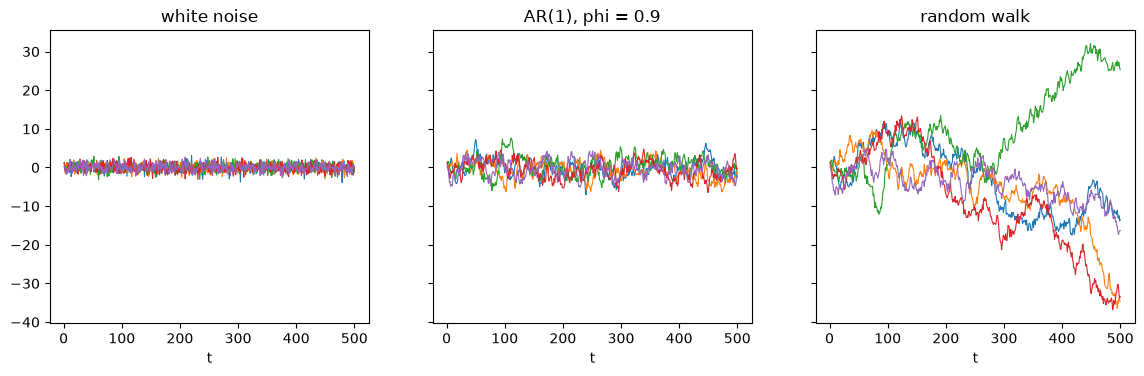

In [2]:
rng = np.random.default_rng(0)
eps = rng.standard_normal((2000, 500))   # white noise, sigma = 1
walk = eps.cumsum(axis=1)                # random walk


def simulate_ar1_paths(phi, shocks):
    # AR(1) paths X_t = phi * X_{t-1} + eps_t started from X_0 = 0, one path per row of shocks
    x = np.zeros_like(shocks)
    x[:, 0] = shocks[:, 0]
    for t in range(1, shocks.shape[1]):
        x[:, t] = phi * x[:, t - 1] + shocks[:, t]
    return x


ar_09 = simulate_ar1_paths(0.9, eps)

fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (name, paths) in zip(axs, [('white noise', eps), ('AR(1), phi = 0.9', ar_09), ('random walk', walk)]):
    ax.plot(np.arange(1, 501), paths[:5].T, lw=0.8)
    ax.set_title(name)
    ax.set_xlabel('t')
plt.show()

**Task 1A.** For `eps`, `ar_09` and `walk`, compute the variance across the 2,000 paths (`np.var`, which divides by the number of paths) at each period $t = 1, \dots, 500$. Report the values at $t$ = 10, 50, 100, 250 and 500 in one table, and plot the variance of each process against $t$.

Reference: at $t$ = 500 the variance is 5.517 for `ar_09` and 509.42 for `walk`; at $t$ = 10 it is 4.423 for `ar_09`.

In [3]:
# Variance across the 2,000 simulated paths at each period t.
periods = np.arange(1, eps.shape[1] + 1)
variances = pd.DataFrame(
    {name: np.var(paths, axis=0) for name, paths in
     [('eps', eps), ('ar_09', ar_09), ('walk', walk)]},
    index=periods,
)

# Show the variance at the requested periods.
selected_periods = [10, 50, 100, 250, 500]
variance_table = variances.loc[selected_periods].rename_axis('t')
variance_table


,eps,ar_09,walk
t,,,
10,0.979804,4.422592,9.620537
50,0.973992,5.176182,48.942034
100,0.946475,5.347006,99.905811
250,0.980599,5.330589,244.064815
500,1.003929,5.517168,509.424292


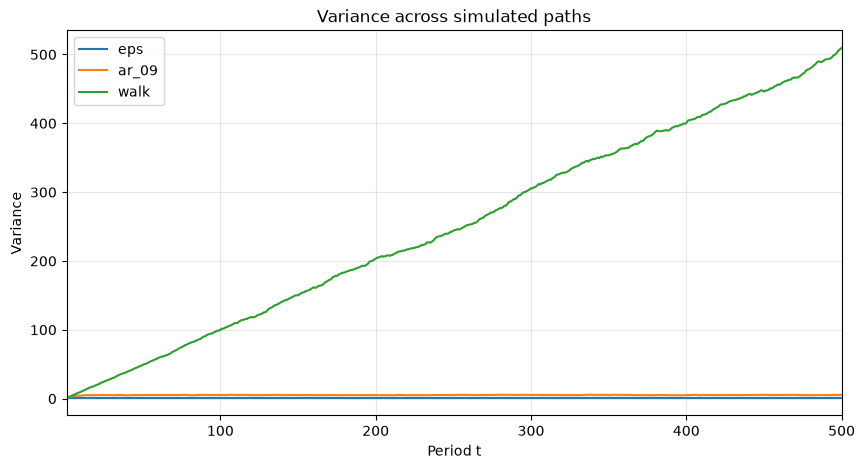

In [4]:
# Plot variance across paths over time.
ax = variances.plot(figsize=(10, 5), linewidth=1.5)
ax.set(title='Variance across simulated paths', xlabel='Period t', ylabel='Variance')
ax.set_xlim(1, eps.shape[1])
ax.grid(True, alpha=0.3)
plt.show()

For the S&P 500, the log price plays the role of $X_t$, and the log return is its first difference: $r_t = X_t - X_{t-1}$. The VIX is a third kind of series: a level, like the price, but not the accumulation of daily changes in anything.

**Task 1B.** Plot `log_price`, `r` and `vix` one above the other. For the periods 1990–1999, 2000–2009, 2010–2019 and 2020–2024, report the mean and the standard deviation of each of the three series in one table.

Reference: the mean of the log price is 637.5, 706.5, 753.5 and 834.0; the standard deviation of the return is 0.889, 1.401, 0.932 and 1.350; the mean of the VIX is 18.46, 22.12, 16.86 and 21.41.

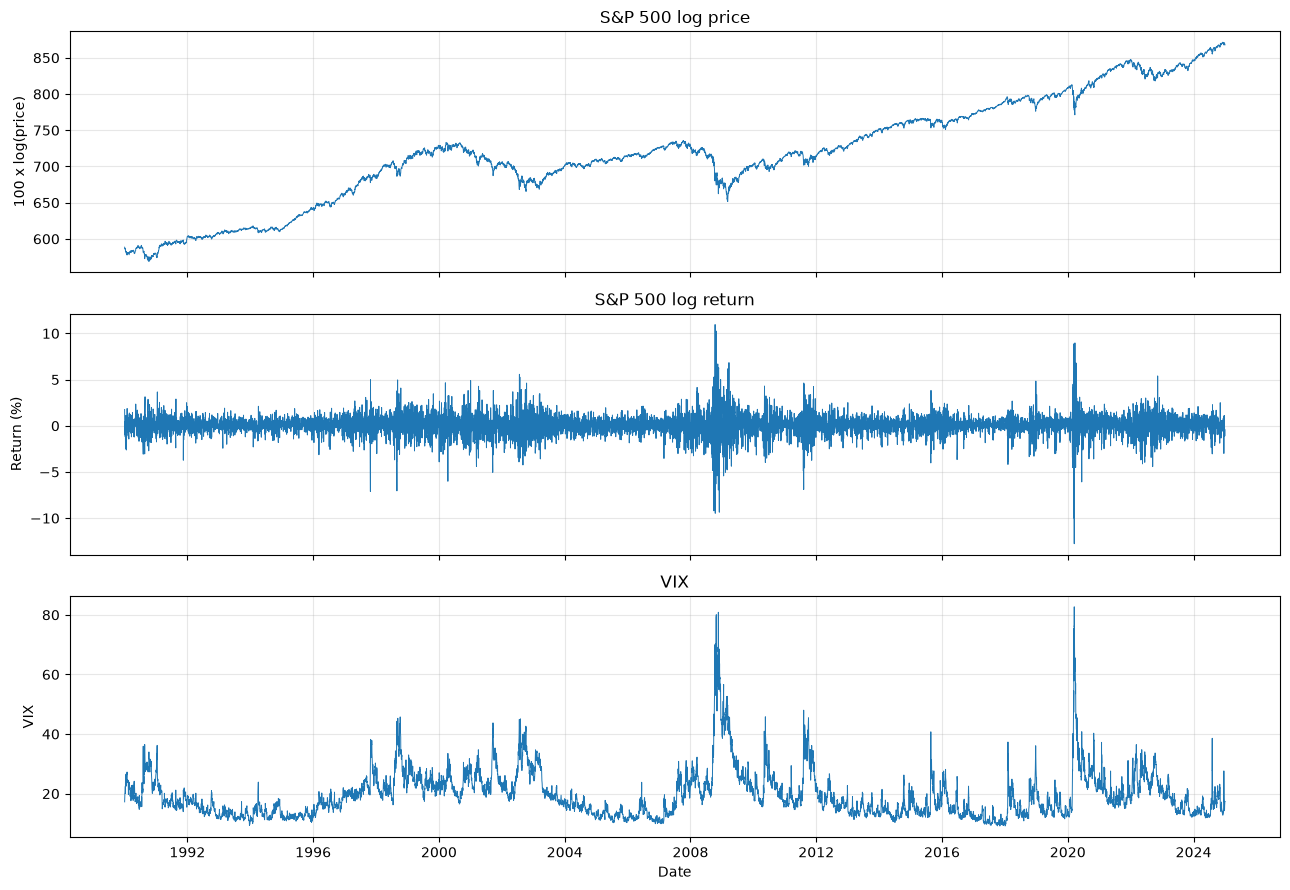

mean        std
period    series                          
1990–1999 log_price  637.536708  44.852571
          r            0.056365   0.888868
          vix         18.461149   5.911218
2000–2009 log_price  706.479932  17.334215
          r           -0.010967   1.400579
          vix         22.118326   9.901104
2010–2019 log_price  753.500090  31.096447
          r            0.042281   0.932053
          vix         16.859046   5.631503
2020–2024 log_price  834.042006  18.339496
          r            0.047623   1.349610
          vix         21.411884   8.261801

In [5]:
# Plot each series separately on a shared time axis.
fig, axs = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, series, title, ylabel in zip(
    axs,
    [log_price, r, vix],
    ['S&P 500 log price', 'S&P 500 log return', 'VIX'],
    ['100 x log(price)', 'Return (%)', 'VIX'],
):
    ax.plot(series.index, series, linewidth=0.7)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
axs[-1].set_xlabel('Date')
fig.tight_layout()
plt.show()

# Mean and sample standard deviation for each series within each period.
periods = [('1990–1999', '1990-01-01', '1999-12-31'),
           ('2000–2009', '2000-01-01', '2009-12-31'),
           ('2010–2019', '2010-01-01', '2019-12-31'),
           ('2020–2024', '2020-01-01', '2024-12-31')]
series_by_name = {'log_price': log_price, 'r': r, 'vix': vix}
rows = []
for period, start, end in periods:
    for name, series in series_by_name.items():
        window = series.loc[start:end]
        rows.append({'period': period, 'series': name,
                     'mean': window.mean(), 'std': window.std()})
summary = pd.DataFrame(rows).set_index(['period', 'series'])
summary


**Question 1.1**

Using the definition of the random walk, derive $\mathrm{Var}(X_t)$ and compare it with Task 1A. Explain why the random walk is not stationary, and why its first difference is.

**Answer:**

$Var(X_t)=t$. Yes data confirm such formula. It is not stationary because the variance is not constant for all t. The first difference is just epsilon which by definition follows the same distribution throughout.

**Question 1.2**

Using Task 1B, which of the three series could plausibly be stationary? Explain why a model fitted to the price level would be hard to use, and why time-series models of prices are built on returns.

**Answer:**
Price level is like random walk while returns is more similar to the first difference. Hence, if the data is not stationary, a time series model would not be able to capture its unstable pattern. Hence, building on returns is a better choice.

# 2. Autocorrelation

The **autocorrelation function** (ACF) of a stationary series is the correlation between observations $k$ periods apart:

$$\rho_k = \frac{\gamma_k}{\gamma_0} = \mathrm{Corr}(X_t, X_{t-k}), \qquad k = 1, 2, \dots$$

It is estimated by the **sample ACF**

$$\hat\rho_k = \frac{\sum_{t=k+1}^{n} (x_t - \bar x)(x_{t-k} - \bar x)}{\sum_{t=1}^{n} (x_t - \bar x)^2},$$

which uses the mean and variance of the whole sample (it differs slightly from the correlation between the series and its lagged copy).

**White noise benchmark.** If the observations are independent and identically distributed, every $\rho_k = 0$, and for large $n$ each $\hat\rho_k$ is approximately $\mathcal{N}(0, 1/n)$. About 95% of the sample autocorrelations should therefore fall inside the band $\pm 1.96/\sqrt{n}$.

**Ljung-Box test.** The Ljung-Box statistic combines the first $m$ sample autocorrelations into one test:

$$Q(m) = n(n+2) \sum_{k=1}^{m} \frac{\hat\rho_k^2}{n - k}.$$

Under the null hypothesis of independent, identically distributed observations, $Q(m)$ is approximately $\chi^2$ with $m$ degrees of freedom. A small p-value is evidence that at least one of $\rho_1, \dots, \rho_m$ is not zero.

**Partial autocorrelation function** (PACF). $X_t$ and $X_{t-2}$ can be correlated simply because both are correlated with $X_{t-1}$. The partial autocorrelation at lag $k$, $\alpha_k$, measures the link that remains once the lags in between are held fixed. It is the coefficient on $X_{t-k}$ in the regression

$$X_t = c + a_1 X_{t-1} + \dots + a_{k-1} X_{t-k+1} + \alpha_k X_{t-k} + u_t,$$

just as a coefficient in a multiple regression (Week 1 Section 4) measures the effect of one regressor with the others held fixed. $\alpha_1 = \rho_1$, since there is nothing in between.

In `statsmodels`, `acf(x, nlags=k)` and `pacf(x, nlags=k, method='ols')` return arrays whose element `j` is the value at lag `j` (element 0 is lag 0 and equals 1). `method='ols'` computes the PACF with the regression above. `acorr_ljungbox(x, lags=[m])` returns $Q(m)$ (`lb_stat`) and its p-value (`lb_pvalue`).

`wn` below is simulated white noise with as many observations as `r`, used as a benchmark. `plot_correlogram` draws autocorrelations as bars together with the white-noise band.

In [6]:
n_obs = len(r)
band = 1.96 / np.sqrt(n_obs)
wn = pd.Series(np.random.default_rng(1).standard_normal(n_obs), index=r.index, name='WN')


def plot_correlogram(values, n, ax, title):
    # values[j] is the (partial) autocorrelation at lag j + 1; the dashed lines are +-1.96 / sqrt(n)
    lags = np.arange(1, len(values) + 1)
    ax.bar(lags, values, width=0.4)
    ax.axhline(0, color='k', lw=0.8)
    for b in (1.96 / np.sqrt(n), -1.96 / np.sqrt(n)):
        ax.axhline(b, color='k', ls='--', lw=0.8)
    ax.set_xlabel('lag')
    ax.set_title(title)

**Task 2A.**

1. Implement the sample ACF formula above yourself. Compute $\hat\rho_1, \dots, \hat\rho_{20}$ of the log return `r` and check them against `acf`.
2. Compute the partial autocorrelation of `r` at lag 2 by running the regression above with `sm.OLS`, and check it against `pacf(..., method='ols')`.

Reference: $\hat\rho_1 = -0.0786$; the partial autocorrelation at lag 2 is -0.0136.

In [7]:
def ACF(x, k):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]
    x_centered = x - x.mean()
    numerator = np.sum(x_centered[k:] * x_centered[:-k])
    denominator = np.sum(x_centered ** 2)
    return numerator / denominator

# Calculate lags 1–20 directly and compare with statsmodels.
acf_manual = np.array([ACF(r, k) for k in range(1, 21)])
acf_statsmodels = acf(r, nlags=20, fft=False)[1:]
acf_comparison = pd.DataFrame(
    {'manual': acf_manual, 'statsmodels': acf_statsmodels},
    index=pd.Index(range(1, 21), name='lag'),
)
display(acf_comparison.round(4))

# PACF at lag 2: regress r_t on a constant, r_(t-1), and r_(t-2).
r_values = np.asarray(r, dtype=float)
y = r_values[2:]
X = sm.add_constant(np.column_stack([r_values[1:-1], r_values[:-2]]))
pacf_lag2_regression = sm.OLS(y, X).fit().params[2]
pacf_lag2_statsmodels = pacf(r, nlags=2, method='ols')[2]
print(f'PACF lag 2 from OLS: {pacf_lag2_regression:.4f}')
print(f'PACF lag 2 from statsmodels: {pacf_lag2_statsmodels:.4f}')


,manual,statsmodels
lag,,
1,-0.0786,-0.0786
2,-0.0073,-0.0073
3,-0.0014,-0.0014
4,-0.0209,-0.0209
5,-0.0179,-0.0179
6,-0.0307,-0.0307
7,0.0156,0.0156
8,-0.0260,-0.0260
9,0.0380,0.0380


PACF lag 2 from OLS: -0.0136
PACF lag 2 from statsmodels: -0.0136


**Task 2B.** For `wn`, `r` and `vix`, compute the sample ACF at lags 1 to 20. In one table, report $\hat\rho_1$, $\hat\rho_{20}$, the number of lags (out of 20) outside the band $\pm 1.96/\sqrt{n}$, and $Q(10)$ with its p-value. Plot the three correlograms side by side with `plot_correlogram`.

Reference: `wn` has 1 lag outside the band and $Q(10)$ = 6.55 (p = 0.767); `r` has 8 lags outside the band and $Q(10)$ = 90.95; `vix` has $\hat\rho_{20}$ = 0.778.

,rho_1,rho_20,outside_band_count,Q(10),p_value
series,,,,,
wn,-0.0115,0.0008,1,6.5468,0.7674
r,-0.0786,0.0073,8,90.9481,0.0000
vix,0.9780,0.7780,20,74740.4338,0.0000


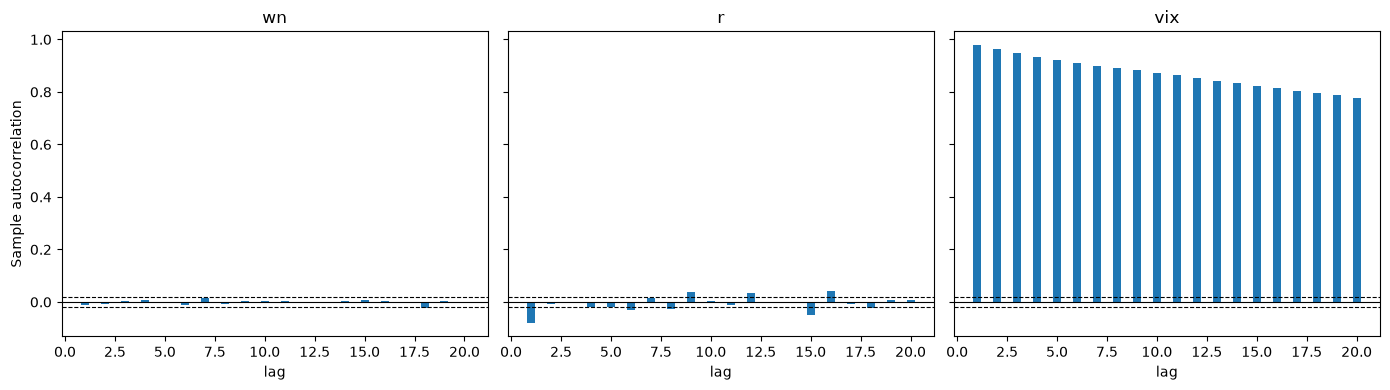

In [8]:
series_by_name = {'wn': wn, 'r': r, 'vix': vix}
acf_by_series = {}
summary_rows = []

for name, series in series_by_name.items():
    values = np.asarray(series, dtype=float)
    values = values[np.isfinite(values)]
    n = len(values)
    acf_values = np.array([ACF(values, k) for k in range(1, 21)])
    acf_by_series[name] = (acf_values, n)
    lb = acorr_ljungbox(values, lags=[10], return_df=True)
    summary_rows.append({
        'series': name,
        'rho_1': acf_values[0],
        'rho_20': acf_values[19],
        'outside_band_count': np.sum(np.abs(acf_values) > 1.96 / np.sqrt(n)),
        'Q(10)': lb['lb_stat'].iloc[0],
        'p_value': lb['lb_pvalue'].iloc[0],
    })

acf_summary = pd.DataFrame(summary_rows).set_index('series')
display(acf_summary.round(4))

fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (name, (acf_values, n)) in zip(axs, acf_by_series.items()):
    plot_correlogram(acf_values, n, ax, name)
axs[0].set_ylabel('Sample autocorrelation')
fig.tight_layout()
plt.show()


**Question 2.1**

In Task 2B, `wn` has a lag outside the band even though it is white noise by construction. How many lags out of 20 would you expect outside the band for white noise, and why does that make a single lag outside the band weak evidence? How does the Ljung-Box test deal with this, and what does it conclude for `wn`?

**Answer:**
0.05*20=1. So 1 is expected.
Ljung-Box test calculate the p-value so it is not just about how many is outside the band, but about the probability that such thing could happen under null hypothesis.
It fails to reject the null hypthesis which states wn is iid.

**Question 2.2**

Compare the correlograms of `r` and `vix` in Task 2B. Taken at face value, what does $\hat\rho_1$ of `r` say about the next day's return after a large fall? What does the ACF of `vix` say about how long a high VIX tends to last? (Section 6 asks whether the face value for `r` can be trusted.)

**Answer:**
Next day is likely to rise. (reversal) since \hat \rho_1 is negative. The correlation for VIX is still high for lag 20 so it suggests the high VIX is likely to last longer than 20.

# 3. AR, MA and ARMA Models

White noise has no memory. The models in this section build memory out of white noise $\varepsilon_t$ (variance $\sigma^2$) in two ways.

- **AR(p)**, autoregressive: the value today is a linear function of the last $p$ values plus a new shock,
$$X_t = c + \phi_1 X_{t-1} + \dots + \phi_p X_{t-p} + \varepsilon_t.$$
- **MA(q)**, moving average: the value today is a combination of today's shock and the last $q$ shocks,
$$X_t = \mu + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \dots + \theta_q \varepsilon_{t-q}.$$
- **ARMA(p, q)** combines both:
$$X_t = c + \phi_1 X_{t-1} + \dots + \phi_p X_{t-p} + \varepsilon_t + \theta_1 \varepsilon_{t-1} + \dots + \theta_q \varepsilon_{t-q}.$$

**AR(1).** Take $X_t = \phi X_{t-1} + \varepsilon_t$ with $|\phi| < 1$. Substituting the equation into itself repeatedly gives

$$X_t = \varepsilon_t + \phi\,\varepsilon_{t-1} + \phi^2 \varepsilon_{t-2} + \phi^3 \varepsilon_{t-3} + \cdots,$$

so a shock from $j$ periods ago still contributes $\phi^j$ of its original size. Three properties follow.

- **Variance**: the shocks are uncorrelated, so $\gamma_0 = \sigma^2 (1 + \phi^2 + \phi^4 + \cdots) = \dfrac{\sigma^2}{1 - \phi^2}$.
- **ACF**: multiplying $X_t = \phi X_{t-1} + \varepsilon_t$ by $X_{t-k}$ and taking expectations gives $\gamma_k = \phi\,\gamma_{k-1}$, because $\varepsilon_t$ is uncorrelated with everything before $t$. Hence $\rho_k = \phi^k$: the ACF decays geometrically and is never exactly zero.
- **PACF**: $X_t$ depends on the past only through $X_{t-1}$, so $\alpha_1 = \phi$ and $\alpha_k = 0$ for $k \ge 2$. In general, the PACF of an AR(p) is zero beyond lag $p$.

**MA(1).** Take $X_t = \varepsilon_t + \theta \varepsilon_{t-1}$. Then $\gamma_0 = (1 + \theta^2)\sigma^2$ and $\gamma_1 = \theta \sigma^2$, so $\rho_1 = \theta / (1 + \theta^2)$. For $k \ge 2$, $X_t$ and $X_{t-k}$ share no shock, so $\rho_k = 0$: the ACF cuts off after lag 1. In general, the ACF of an MA(q) is zero beyond lag $q$. The PACF of an MA(1) decays instead of cutting off: when $|\theta| < 1$ the model can be rewritten as $X_t = \theta X_{t-1} - \theta^2 X_{t-2} + \theta^3 X_{t-3} - \dots + \varepsilon_t$, so every past value carries some information that the values in between do not.

| | ACF | PACF |
|---|---|---|
| AR(p) | decays gradually | zero beyond lag $p$ |
| MA(q) | zero beyond lag $q$ | decays gradually |
| ARMA(p, q) | decays gradually | decays gradually |

An MA process is always stationary. An AR process is stationary only if the effect of a shock fades over time; for the AR(1), this means $|\phi| < 1$.

`simulate_arma` below simulates an ARMA process with standard normal shocks ($\sigma = 1$). `ArmaProcess` takes the coefficients in the form $1 - \phi_1 B - \dots$ and $1 + \theta_1 B + \dots$, where $B$ shifts the series back one period; the function handles the signs. The first 200 draws are discarded so that each series starts in its stationary state. `ArmaProcess(...).acf(m)` and `.pacf(m)` return the theoretical values at lags 0 to $m - 1$.

In [9]:
def make_process(phi, theta):
    return ArmaProcess(np.r_[1, -np.asarray(phi, dtype=float)], np.r_[1, np.asarray(theta, dtype=float)])


def simulate_arma(phi, theta, n, seed, mean=0.0):
    # n observations of an ARMA process with AR coefficients phi, MA coefficients theta and N(0, 1) shocks
    rng = np.random.default_rng(seed)
    x = make_process(phi, theta).generate_sample(n, distrvs=rng.standard_normal, burnin=200)
    return mean + pd.Series(x)


true_params = {'AR(1)': ([0.7], []), 'AR(2)': ([0.5, 0.3], []), 'MA(1)': ([], [0.8]), 'ARMA(1,1)': ([0.7], [0.4])}
sims = {name: simulate_arma(phi, theta, 1000, seed=i + 1) for i, (name, (phi, theta)) in enumerate(true_params.items())}

**Task 3A.** For each of the four series in `sims`, compute the sample ACF and PACF (`method='ols'`) at lags 1 to 10, and the theoretical values from `make_process(phi, theta)`. Show sample and theoretical values side by side for lags 1 to 4, and plot the sample ACF and PACF of each series (one row per series) with `plot_correlogram`, marking the theoretical values on each panel.

Reference: for AR(1) the sample ACF at lags 1 and 2 is 0.697 and 0.503 and the sample PACF at lag 2 is 0.037; for MA(1) the sample ACF at lag 2 is -0.009 and the sample PACF at lag 2 is -0.324.

sample_acf  theoretical_acf  sample_pacf  theoretical_pacf
series    lag                                                            
AR(1)     1         0.697            0.700        0.697             0.700
          2         0.503            0.490        0.037             0.000
          3         0.354            0.343       -0.018            -0.000
          4         0.239            0.240       -0.021             0.000
AR(2)     1         0.693            0.714        0.695             0.714
          2         0.622            0.657        0.271             0.300
          3         0.493            0.543       -0.019            -0.000
          4         0.388            0.469       -0.051             0.000
MA(1)     1         0.487            0.488        0.489             0.488
          2        -0.009            0.000       -0.324            -0.312
          3        -0.006            0.000        0.232             0.221
          4         0.018            0.000       -0.147            -0.165
ARMA(1,1) 1         0.824            0.819        0.828             0.819
          2         0.590            0.573       -0.283            -0.294
          3         0.409            0.401        0.058             0.116
          4         0.273            0.281       -0.041            -0.046

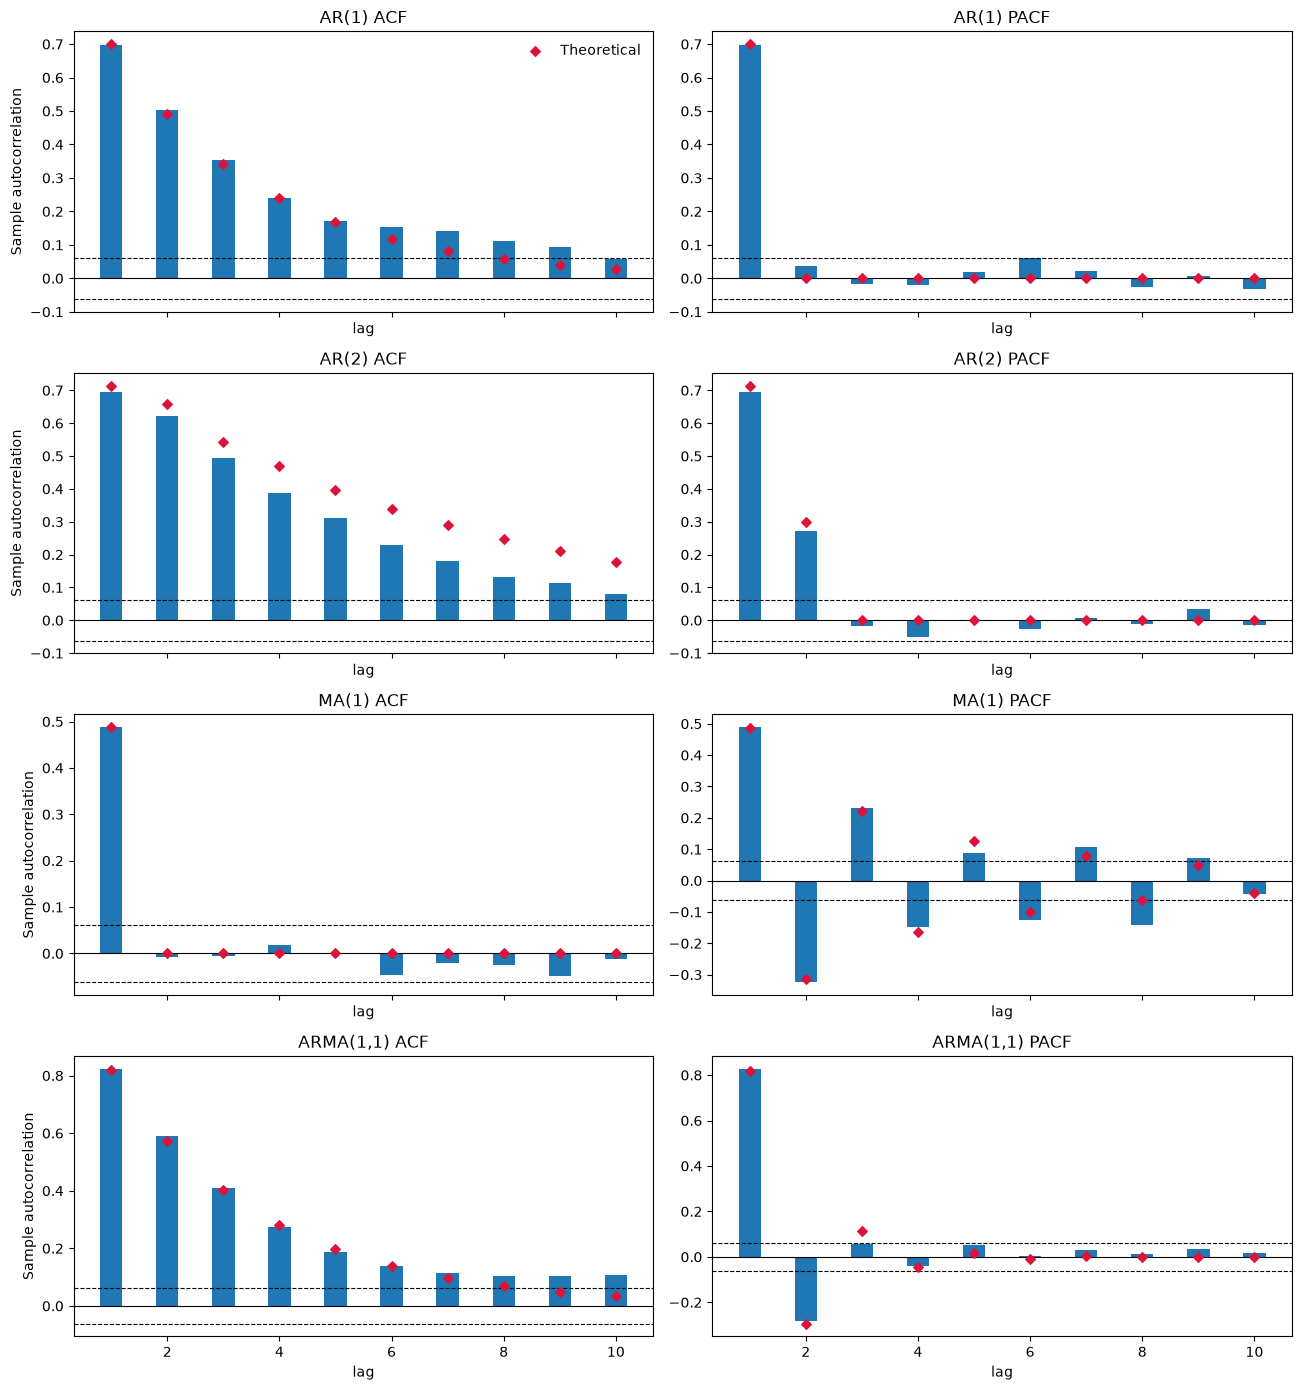

In [10]:
# Compute sample and theoretical ACF/PACF values for each simulated process.
results_3a = {}
rows_3a = []

for name, series in sims.items():
    phi, theta = true_params[name]
    process = make_process(phi, theta)
    values = np.asarray(series, dtype=float)
    n = len(values)

    sample_acf = acf(values, nlags=10, fft=False)[1:]
    sample_pacf = pacf(values, nlags=10, method='ols')[1:]
    theoretical_acf = process.acf(lags=11)[1:]
    theoretical_pacf = process.pacf(lags=11)[1:]

    results_3a[name] = {
        'n': n,
        'sample_acf': sample_acf,
        'sample_pacf': sample_pacf,
        'theoretical_acf': theoretical_acf,
        'theoretical_pacf': theoretical_pacf,
    }

    for lag in range(1, 5):
        rows_3a.append({
            'series': name,
            'lag': lag,
            'sample_acf': sample_acf[lag - 1],
            'theoretical_acf': theoretical_acf[lag - 1],
            'sample_pacf': sample_pacf[lag - 1],
            'theoretical_pacf': theoretical_pacf[lag - 1],
        })

comparison_3a = pd.DataFrame(rows_3a).set_index(['series', 'lag'])
display(comparison_3a.round(3))

# Plot each sample correlogram and overlay the corresponding theoretical values.
fig, axs = plt.subplots(len(sims), 2, figsize=(13, 14), sharex=True)
for row, (name, result) in enumerate(results_3a.items()):
    for col, (key, title) in enumerate([
        ('acf', 'ACF'),
        ('pacf', 'PACF'),
    ]):
        ax = axs[row, col]
        sample = result[f'sample_{key}']
        theoretical = result[f'theoretical_{key}']
        plot_correlogram(sample, result['n'], ax, f'{name} {title}')
        lags = np.arange(1, 11)
        ax.scatter(lags, theoretical, marker='D', s=24, color='crimson',
                   label='Theoretical', zorder=3)
        if row == 0 and col == 0:
            ax.legend(frameon=False)
        if col == 0:
            ax.set_ylabel('Sample autocorrelation')

fig.tight_layout()
plt.show()


**Task 3B.** For $\phi$ = 0.5, 0.9 and 0.99, simulate an AR(1) of 5,000 observations with `simulate_arma([phi], [], 5000, seed=10)`. For each, report:

1. the sample variance (the pandas `.var()` default, which divides by $n - 1$) and the theoretical variance $1/(1 - \phi^2)$;
2. the **half-life** of a shock, the number of periods after which only half of it remains: the $h$ that solves $\phi^h = 0.5$.

Plot the first 500 observations of the three series.

Reference: the half-lives are 1.0, 6.6 and 69.0 periods; for $\phi$ = 0.9 the sample variance is 5.229.

,sample_variance,theoretical_variance,half_life_periods
phi,,,
0.50,1.306,1.333,1.000
0.90,5.229,5.263,6.579
0.99,48.649,50.251,68.968


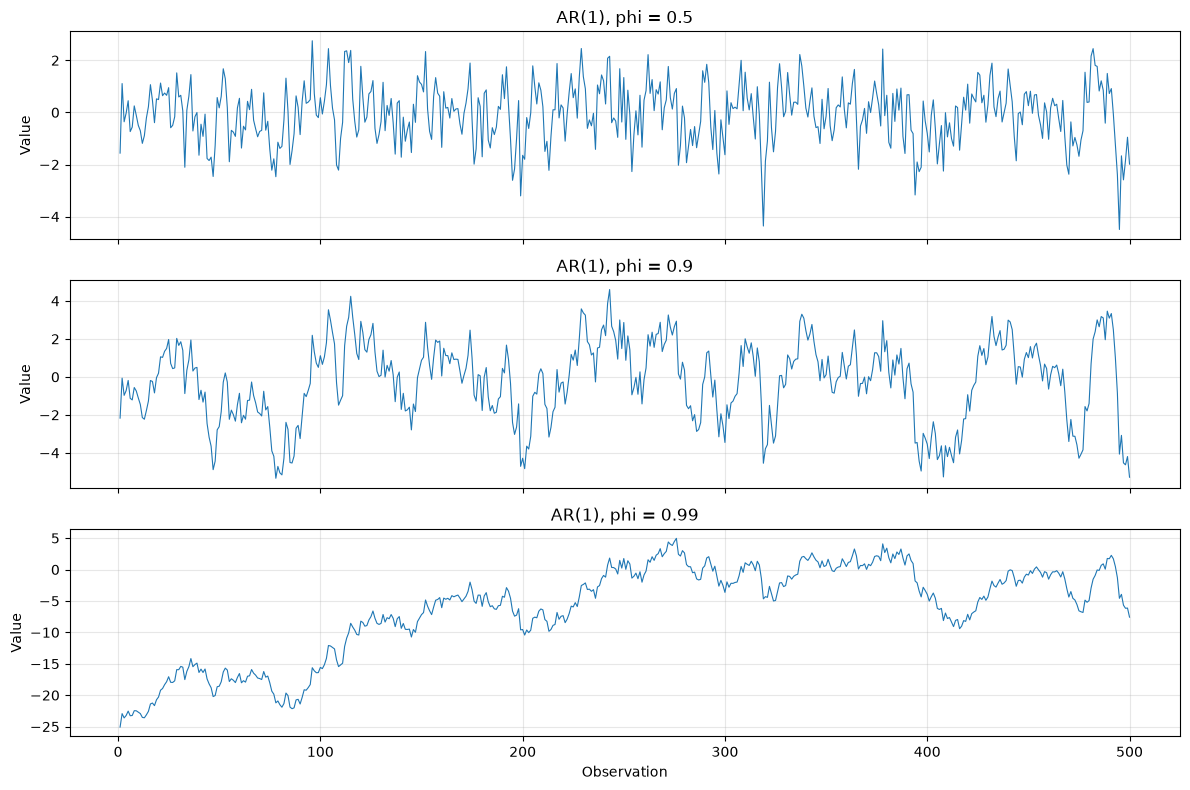

In [11]:
# Simulate the three AR(1) processes and compare sample and theoretical quantities.
phis_3b = [0.5, 0.9, 0.99]
ar1_series_3b = {}
rows_3b = []

for phi in phis_3b:
    series = simulate_arma([phi], [], 5000, seed=10)
    ar1_series_3b[phi] = series
    half_life = np.log(0.5) / np.log(phi)
    rows_3b.append({
        'phi': phi,
        'sample_variance': series.var(),
        'theoretical_variance': 1 / (1 - phi ** 2),
        'half_life_periods': half_life,
    })

summary_3b = pd.DataFrame(rows_3b).set_index('phi')
display(summary_3b.round(3))

# Compare the first 500 observations on a common set of axes.
fig, axs = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, (phi, series) in zip(axs, ar1_series_3b.items()):
    ax.plot(np.arange(1, 501), series.iloc[:500], linewidth=0.8)
    ax.set_title(f'AR(1), phi = {phi}')
    ax.set_ylabel('Value')
    ax.grid(True, alpha=0.3)
axs[-1].set_xlabel('Observation')
fig.tight_layout()
plt.show()


**Question 3.1**

In Task 3A, the AR(1) has a clearly non-zero sample ACF at lag 2 but a sample PACF at lag 2 close to zero. Explain, in terms of what each of the two measures, how $X_t$ and $X_{t-2}$ can be correlated and yet have no partial autocorrelation.

**Answer:**
ACF at lag 2 measures how $X_t$ correlate with $X_{t-2}$. This is nonzero because they both correlate with $X_{t-1}$ in AR(1). PACF measures how $X_t$ linked with $X_{t-2}$ after accounting the effect of $X_{t-1}$.

**Question 3.2**

What does $\phi$ in an AR(1) tell you about how quickly a shock dies out? Using Task 3B, describe what happens as $\phi$ approaches 1, and connect the limit to the random walk of Section 1.

**Answer:**
The larger the $\phi$, the slower the shock dies out. Hence, when $\phi$ approaches 1, the series is less and less stationary and the variance will increase. AR(1) is the random walk when $\phi=1$ and the $\mathrm Var(X_t)$ will be infinite as $t$ goes to infinity.

# 4. ARIMA and Model Building

**Unit roots and differencing.** The random walk is an AR(1) with $\phi = 1$; it is said to have a **unit root**. It is not stationary, but its first difference $\Delta X_t = X_t - X_{t-1} = \varepsilon_t$ is. A series that has to be differenced $d$ times to become stationary is **integrated of order $d$**. An **ARIMA(p, d, q)** model says that the $d$-th difference of the series follows an ARMA(p, q). For example, a log price that follows ARIMA(p, 1, q) has log returns that follow ARMA(p, q).

**Testing for a unit root.** The **augmented Dickey-Fuller (ADF)** test decides whether a series needs differencing. It runs the regression

$$\Delta X_t = c + \gamma X_{t-1} + \delta_1 \Delta X_{t-1} + \dots + \delta_m \Delta X_{t-m} + u_t.$$

For an AR(1), $\gamma = \phi - 1$, so a unit root means $\gamma = 0$; the lagged differences absorb any additional short-run autocorrelation. The null hypothesis is a unit root ($\gamma = 0$) and the alternative is a stationary series ($\gamma < 0$). Under the null, the t-statistic of $\hat\gamma$ does not follow a t-distribution, so it is compared with special critical values (about -2.86 at the 5% level). `adfuller(x)` returns the statistic, its p-value and further details. Failing to reject means that the data are consistent with a unit root, not that a unit root has been proven.

**Choosing p and q.** The patterns in Section 3 suggest candidate orders, but real ACFs and PACFs are rarely that clean. The usual practice is to fit a range of candidates by maximum likelihood and compare them with the **Akaike information criterion**

$$\mathrm{AIC} = -2 \log L + 2k,$$

where $\log L$ is the maximized log-likelihood and $k$ the number of estimated parameters. Adding a parameter can only raise $\log L$, just as adding a regressor can only raise the in-sample $R^2$; the $2k$ term is the penalty for complexity. Lower is better. The penalty is charged for the parameters of each model, not for the number of models compared: when many candidates are fitted to the same sample, one of them can come out a few points lower than the rest by chance alone, so a difference of about 2 or less between two models is weak evidence that one is better. The **BIC** uses the heavier penalty $k \log n$ in place of $2k$.

**Checking the residuals.** If a model has captured the autocorrelation in the series, its residuals should be white noise. Apply the Ljung-Box test to the residuals with `model_df=p+q`, which subtracts the number of estimated ARMA coefficients from the degrees of freedom.

In `statsmodels`, `ARIMA(x, order=(p, d, q), trend=...).fit()` fits a model. `trend='n'` means no constant, `trend='c'` a constant (allowed only when $d = 0$; the reported `const` is then the mean of the series), and `trend='t'` a linear time trend in $X_t$, which with $d = 1$ amounts to a constant drift in $\Delta X_t$. The result has `.params`, `.aic`, `.bic`, `.resid`, `.fittedvalues` and `.get_forecast(h)`. With $d = 1$ the first residual is just the first observation, so drop it before testing the residuals. For some orders `statsmodels` warns that it cannot use its usual starting values for the optimization; the fit still runs.

`arima_sim` below is a simulated ARIMA(1, 1, 1): its first difference is an ARMA(1, 1) with $\phi = 0.6$ and $\theta = 0.3$.

In [12]:
arima_sim = simulate_arma([0.6], [0.3], 1000, seed=5).cumsum()

**Task 4A.** Plot `arima_sim` and its first difference. Run the ADF test on both, report the statistic and p-value, and decide $d$.

Reference: the ADF statistic is 0.040 (p = 0.962) for the level and -12.010 for the first difference.

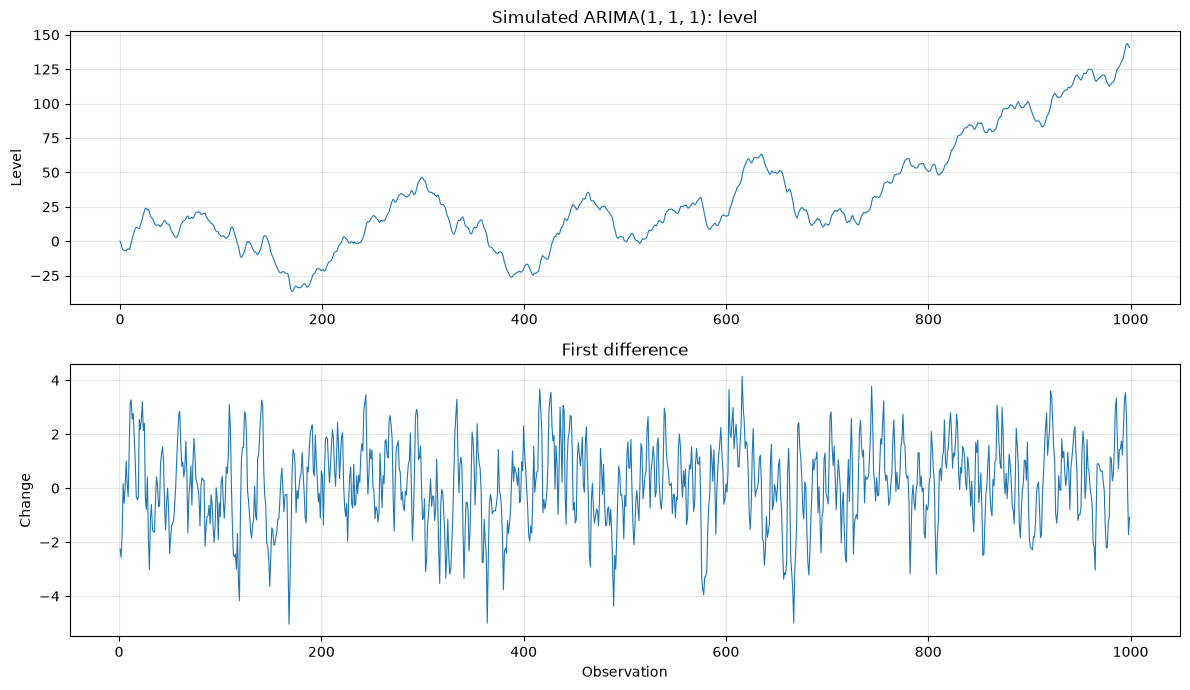

/var/folders/9h/l43cv54x03j1zmdc0g4vt_kr0000gn/T/ipykernel_10746/2746659305.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_level = adfuller(arima_sim)
/var/folders/9h/l43cv54x03j1zmdc0g4vt_kr0000gn/T/ipykernel_10746/2746659305.py:15: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_difference = adfuller(arima_diff)


,ADF statistic,p-value
series,,
Level,0.0399,0.9617
First difference,-12.0098,0.0000


In [13]:
# Plot the simulated level and its first difference.
arima_diff = arima_sim.diff().dropna()
fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=False)
axs[0].plot(arima_sim.index, arima_sim, linewidth=0.8)
axs[0].set(title='Simulated ARIMA(1, 1, 1): level', ylabel='Level')
axs[0].grid(True, alpha=0.3)
axs[1].plot(arima_diff.index, arima_diff, linewidth=0.8)
axs[1].set(title='First difference', xlabel='Observation', ylabel='Change')
axs[1].grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# ADF null hypothesis: the series has a unit root.
adf_level = adfuller(arima_sim)
adf_difference = adfuller(arima_diff)
adf_summary_4a = pd.DataFrame(
    [
        {'series': 'Level', 'ADF statistic': adf_level[0], 'p-value': adf_level[1]},
        {'series': 'First difference', 'ADF statistic': adf_difference[0], 'p-value': adf_difference[1]},
    ]
).set_index('series')
display(adf_summary_4a.round(4))


**Task 4B.** Fit ARIMA(p, 1, q) with `trend='n'` to `arima_sim` for every $p, q \in \{0, 1, 2, 3\}$. Show the AIC, the BIC and the Ljung-Box p-value of the residuals at lag 10 as three 4 × 4 tables ($p$ in rows, $q$ in columns), and identify the orders chosen by AIC and by BIC.

Reference: ARIMA(1, 1, 1) has AIC 2797.74; ARIMA(1, 1, 0) has AIC 2883.62 and a Ljung-Box p-value below 0.0001.

In [14]:
# Fit every ARIMA(p, 1, q) candidate and collect fit and residual diagnostics.
orders_4b = range(4)
fits_4b = {}
rows_4b = []

for p_order in orders_4b:
    for q_order in orders_4b:
        fit = ARIMA(arima_sim, order=(p_order, 1, q_order), trend='n').fit()
        fits_4b[(p_order, q_order)] = fit
        # With d=1, the first residual is the initial observation rather than an innovation.
        residuals = fit.resid.iloc[1:] if isinstance(fit.resid, pd.Series) else fit.resid[1:]
        lb_pvalue = acorr_ljungbox(
            residuals, lags=[10], model_df=p_order + q_order, return_df=True
        )['lb_pvalue'].iloc[0]
        rows_4b.append({
            'p': p_order,
            'q': q_order,
            'AIC': fit.aic,
            'BIC': fit.bic,
            'Ljung-Box p-value': lb_pvalue,
        })

results_4b = pd.DataFrame(rows_4b).set_index(['p', 'q'])
aic_table_4b = results_4b['AIC'].unstack('q')
bic_table_4b = results_4b['BIC'].unstack('q')
ljung_box_table_4b = results_4b['Ljung-Box p-value'].unstack('q')

display(aic_table_4b.round(2).rename_axis(index='p', columns='q'))
display(bic_table_4b.round(2).rename_axis(index='p', columns='q'))
display(ljung_box_table_4b.round(4).rename_axis(index='p', columns='q'))

best_aic_4b = results_4b['AIC'].idxmin()
best_bic_4b = results_4b['BIC'].idxmin()
print(f'Lowest AIC: ARIMA{best_aic_4b[0], 1, best_aic_4b[1]}')
print(f'Lowest BIC: ARIMA{best_bic_4b[0], 1, best_bic_4b[1]}')

/Users/admin/.venvs/vscode-kernel/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/Users/admin/.venvs/vscode-kernel/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


q,0,1,2,3
p,,,,
0,3715.89,3027.26,2865.53,2821.16
1,2883.62,2797.74,2799.68,2801.55
2,2811.29,2799.67,2801.74,2803.19
3,2803.18,2801.54,2803.67,2805.31


q,0,1,2,3
p,,,,
0,3720.79,3037.07,2880.25,2840.79
1,2893.43,2812.46,2819.31,2826.09
2,2826.01,2819.30,2826.27,2832.63
3,2822.80,2826.07,2833.11,2839.66


q,0,1,2,3
p,,,,
0,0.0000,0.0000,0.0000,0.0007
1,0.0000,0.7465,0.6495,0.5576
2,0.0199,0.6500,0.5328,0.5023
3,0.2761,0.5607,0.4024,0.3337


Lowest AIC: ARIMA(np.int64(1), 1, np.int64(1))
Lowest BIC: ARIMA(np.int64(1), 1, np.int64(1))


Now the same procedure for real data.

**Task 4C.**

1. Run the ADF test on `log_price` in levels and first differences, and on `r` and `vix_m` in levels. Use $d=1$ for `log_price`, and $d=0$ for `r` and `vix_m`.
2. Plot the sample ACF and PACF of `vix_m` at lags 1 to 24 with `plot_correlogram`. Which order do they suggest?
3. Fit ARIMA(p, 0, q) with `trend='c'` to `vix_m` for every $p, q \in \{0, 1, 2, 3\}$. Show the AIC, the BIC and the Ljung-Box p-value of the residuals at lag 10 as three 4 × 4 tables, and identify the orders chosen by AIC and by BIC.

Reference: the ADF p-value is 0.9186 for the log price and below 0.0001 for `vix_m`; ARIMA(1, 0, 0) has AIC 2342.74, BIC 2354.86 and a Ljung-Box p-value of 0.0811; the lowest AIC is 2334.16.


In [15]:
series_for_adf_4c = {
    'log_price': [('Level', log_price), ('First difference', log_price.diff().dropna())],
    'r': [('Level', r)],
    'vix_m': [('Level', vix_m)],
}
adf_rows_4c = []

for name, versions in series_for_adf_4c.items():
    for form, values in versions:
        values = values.dropna()
        result = adfuller(values)
        adf_rows_4c.append({
            'series': name,
            'form': form,
            'ADF statistic': result[0],
            'p-value': result[1],
            'used lags': result[2],
            'observations': result[3],
        })

adf_comparison_4c = pd.DataFrame(adf_rows_4c).set_index(['series', 'form'])
display(adf_comparison_4c.round(4))
print('Chosen d: log_price = 1; r = 0; vix_m = 0.')


/var/folders/9h/l43cv54x03j1zmdc0g4vt_kr0000gn/T/ipykernel_10746/402416998.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values)
/var/folders/9h/l43cv54x03j1zmdc0g4vt_kr0000gn/T/ipykernel_10746/402416998.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(values)
/var/folders/9h/l43cv54x03j1zmdc0g4vt_kr0000gn/T/ipykernel_10746/4

ADF statistic  p-value  used lags  observations
series    form                                                             
log_price Level                   -0.3471   0.9186         34          8782
          First difference       -17.2077   0.0000         33          8782
r         Level                  -17.1909   0.0000         33          8783
vix_m     Level                   -5.0560   0.0000          2           417

Chosen d: log_price = 1; r = 0; vix_m = 0.


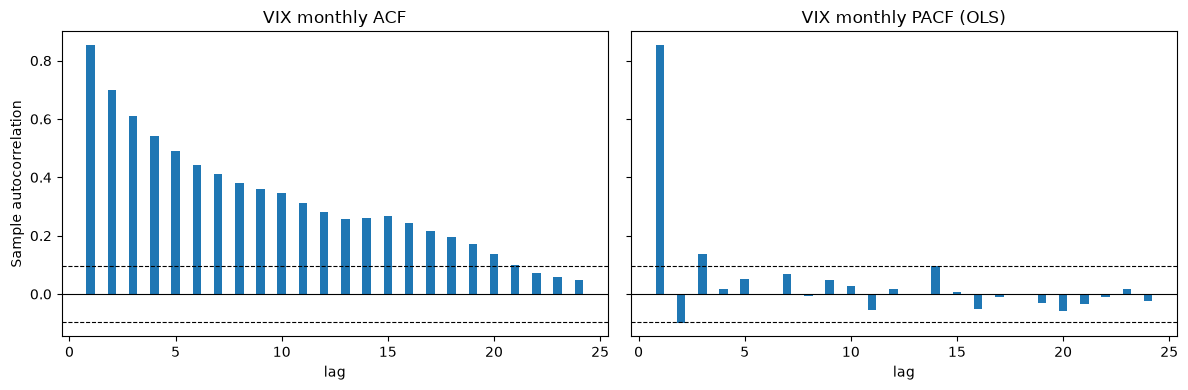

q=22 and p=3


In [16]:
#Inspect the sample ACF and PACF of monthly VIX.
vix_values_4c = vix_m.dropna()
vix_acf_4c = acf(vix_values_4c, nlags=24, fft=False)[1:]
vix_pacf_4c = pacf(vix_values_4c, nlags=24, method='ols')[1:]

fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
plot_correlogram(vix_acf_4c, len(vix_values_4c), axs[0], 'VIX monthly ACF')
plot_correlogram(vix_pacf_4c, len(vix_values_4c), axs[1], 'VIX monthly PACF (OLS)')
axs[0].set_ylabel('Sample autocorrelation')
fig.tight_layout()
plt.show()
print("q=22 and p=3")

In [17]:
fits_4c = {}
rows_4c = []

for p_order in range(4):
    for q_order in range(4):
        fit = ARIMA(vix_m, order=(p_order, 0, q_order), trend='c').fit()
        fits_4c[(p_order, q_order)] = fit
        lb_pvalue = acorr_ljungbox(
            fit.resid, lags=[10], model_df=p_order + q_order, return_df=True
        )['lb_pvalue'].iloc[0]
        rows_4c.append({
            'p': p_order,
            'q': q_order,
            'AIC': fit.aic,
            'BIC': fit.bic,
            'Ljung-Box p-value': lb_pvalue,
        })

results_4c = pd.DataFrame(rows_4c).set_index(['p', 'q'])
aic_table_4c = results_4c['AIC'].unstack('q')
bic_table_4c = results_4c['BIC'].unstack('q')
ljung_box_table_4c = results_4c['Ljung-Box p-value'].unstack('q')

display(aic_table_4c.round(2).rename_axis(index='p', columns='q'))
display(bic_table_4c.round(2).rename_axis(index='p', columns='q'))
display(ljung_box_table_4c.round(4).rename_axis(index='p', columns='q'))

best_aic_4c = results_4c['AIC'].idxmin()
best_bic_4c = results_4c['BIC'].idxmin()
print(f'Lowest AIC: ARIMA{best_aic_4c[0], 0, best_aic_4c[1]}')
print(f'Lowest BIC: ARIMA{best_bic_4c[0], 0, best_bic_4c[1]}')

/Users/admin/.venvs/vscode-kernel/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/Users/admin/.venvs/vscode-kernel/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/Users/admin/.venvs/vscode-kernel/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/Users/admin/.venvs/vscode-kernel/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


q,0,1,2,3
p,,,,
0,2885.71,2554.25,2450.55,2400.90
1,2342.74,2339.00,2334.16,2335.58
2,2340.71,2336.73,2334.70,2336.38
3,2334.61,2336.23,2336.19,2337.94


q,0,1,2,3
p,,,,
0,2893.79,2566.37,2466.71,2421.10
1,2354.86,2355.16,2354.36,2359.82
2,2356.87,2356.93,2358.94,2364.67
3,2354.82,2360.47,2364.47,2370.26


q,0,1,2,3
p,,,,
0,0.0000,0.0000,0.0000,0.0000
1,0.0811,0.2187,0.6709,0.5841
2,0.1459,0.4668,0.6789,0.5957
3,0.6015,0.5323,0.6473,0.5653


Lowest AIC: ARIMA(np.int64(1), 0, np.int64(2))
Lowest BIC: ARIMA(np.int64(1), 0, np.int64(2))


**Task 4D.** Check which model forecasts better on data it has not seen.

1. Fit ARIMA(1, 0, 0) and ARIMA(1, 0, 2), both with `trend='c'`, to `vix_m` through 2014. Report the coefficients of each.
2. Apply each fitted model to the full series with `.apply(vix_m)`, keeping the estimated coefficients fixed, and use its `.fittedvalues` from 2015 onward as the one-step-ahead forecasts.
3. Compare both models with the training-mean and random-walk forecasts, where the random walk predicts next month's VIX using this month's (`vix_m.shift(1)`). Report out-of-sample $R^2$ relative to each benchmark and RMSE for all four forecasts.


In [18]:
# Fit ARIMA(1, 0, 0) and ARIMA(1, 0, 2) through 2014 only.
train_vix_4d = vix_m.loc[:'2014-12-01']
orders_4d = {'ARIMA(1,0,0)': (1, 0, 0), 'ARIMA(1,0,2)': (1, 0, 2)}
fits_4d = {
    name: ARIMA(train_vix_4d, order=order, trend='c').fit()
    for name, order in orders_4d.items()
}

# Estimated coefficients for each training-period fit.
coefficients_4d = pd.DataFrame({name: fit.params for name, fit in fits_4d.items()})
display(coefficients_4d.round(4))

# Apply the fixed parameters to the full series; fittedvalues are one-step forecasts.
forecast_start_4d = pd.Timestamp('2015-01-01')
actual_4d = vix_m.loc[forecast_start_4d:]
forecasts_4d = {}
for name, fit in fits_4d.items():
    applied = fit.apply(vix_m)
    forecasts_4d[name] = pd.Series(applied.fittedvalues, index=vix_m.index).loc[forecast_start_4d:]

# Benchmark forecasts: fixed training mean and previous month's observed VIX.
forecasts_4d['Training mean'] = pd.Series(train_vix_4d.mean(), index=actual_4d.index)
forecasts_4d['Random walk'] = vix_m.shift(1).loc[forecast_start_4d:]
forecast_frame_4d = pd.DataFrame(forecasts_4d).join(actual_4d.rename('actual')).dropna()

sse_training_mean_4d = ((forecast_frame_4d['actual'] - forecast_frame_4d['Training mean']) ** 2).sum()
sse_random_walk_4d = ((forecast_frame_4d['actual'] - forecast_frame_4d['Random walk']) ** 2).sum()
metric_rows_4d = []
for name in forecasts_4d:
    errors = forecast_frame_4d['actual'] - forecast_frame_4d[name]
    sse = (errors ** 2).sum()
    metric_rows_4d.append({
        'forecast': name,
        'R2 vs training mean': 1 - sse / sse_training_mean_4d,
        'R2 vs random walk': 1 - sse / sse_random_walk_4d,
        'RMSE': np.sqrt((errors ** 2).mean()),
    })
metrics_4d = pd.DataFrame(metric_rows_4d).set_index('forecast')
display(metrics_4d.round(4))


,"ARIMA(1,0,0)","ARIMA(1,0,2)"
ar.L1,0.8868,0.8751
const,19.9602,19.9609
ma.L1,NaN,0.2004
ma.L2,NaN,-0.1310
sigma2,12.5173,11.8202


,R2 vs training mean,R2 vs random walk,RMSE
forecast,,,
"ARIMA(1,0,0)",0.5278,0.0883,4.7127
"ARIMA(1,0,2)",0.5102,0.0545,4.7994
Training mean,0.0000,-0.9306,6.8578
Random walk,0.4820,0.0000,4.9357


**Question 4.1**

Why should the search over $p$ and $q$ in Task 4B be limited to small orders? What would you expect to happen if you searched up to $p = q = 10$, and why does the AIC penalty protect against this only partly? Use the AIC differences between the best few models in your table.

In [19]:
# Demonstrate the effect of a high-order model using the Task 4D train/test split.
# All candidate models are estimated through 2014 and evaluated from 2015 onward.
train_vix_q41 = vix_m.loc[:'2014-12-01']
test_start_q41 = pd.Timestamp('2015-01-01')
actual_q41 = vix_m.loc[test_start_q41:]
orders_q41 = {
    'ARIMA(1,0,0)': (1, 0, 0),
    'ARIMA(1,0,2)': (1, 0, 2),
    'ARIMA(10,0,10)': (10, 0, 10),
}
fits_q41 = {}
rows_q41 = []
forecasts_q41 = {}

for name, order in orders_q41.items():
    fit = ARIMA(train_vix_q41, order=order, trend='c').fit()
    fits_q41[name] = fit
    # The high-order model has p+q=20 parameters, so an adjusted Ljung-Box
    # test at lag 10 has no positive degrees of freedom. Use lag 30 for that test.
    test_lag = max(10, order[0] + order[2] + 1)
    lb = acorr_ljungbox(
        fit.resid, lags=[test_lag], model_df=order[0] + order[2], return_df=True
    )
    applied = fit.apply(vix_m)
    forecasts_q41[name] = pd.Series(applied.fittedvalues, index=vix_m.index).loc[test_start_q41:]
    rows_q41.append({
        'model': name,
        'AIC (training)': fit.aic,
    })

fit_diagnostics_q41 = pd.DataFrame(rows_q41).set_index('model')
display(fit_diagnostics_q41.round(4))

# Compare held-out forecasts with the same benchmarks as Task 4D.
forecasts_q41['Training mean'] = pd.Series(train_vix_q41.mean(), index=actual_q41.index)
forecasts_q41['Random walk'] = vix_m.shift(1).loc[test_start_q41:]
forecast_frame_q41 = pd.DataFrame(forecasts_q41).join(actual_q41.rename('actual')).dropna()
sse_mean_q41 = ((forecast_frame_q41['actual'] - forecast_frame_q41['Training mean']) ** 2).sum()
sse_rw_q41 = ((forecast_frame_q41['actual'] - forecast_frame_q41['Random walk']) ** 2).sum()
metric_rows_q41 = []
for name in forecasts_q41:
    errors = forecast_frame_q41['actual'] - forecast_frame_q41[name]
    sse = (errors ** 2).sum()
    metric_rows_q41.append({
        'forecast': name,
        'R2 vs training mean': 1 - sse / sse_mean_q41,
        'R2 vs random walk': 1 - sse / sse_rw_q41,
        'RMSE': np.sqrt((errors ** 2).mean()),
    })
metrics_q41 = pd.DataFrame(metric_rows_q41).set_index('forecast')
display(metrics_q41.round(4))


/Users/admin/.venvs/vscode-kernel/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/Users/admin/.venvs/vscode-kernel/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,AIC (training)
model,
"ARIMA(1,0,0)",1617.0409
"ARIMA(1,0,2)",1603.9899
"ARIMA(10,0,10)",1625.9203


,R2 vs training mean,R2 vs random walk,RMSE
forecast,,,
"ARIMA(1,0,0)",0.5278,0.0883,4.7127
"ARIMA(1,0,2)",0.5102,0.0545,4.7994
"ARIMA(10,0,10)",0.4748,-0.0139,4.9700
Training mean,0.0000,-0.9306,6.8578
Random walk,0.4820,0.0000,4.9357


**Answer:**
Large p and q will increase the complexity of the model and make it hard to interpret. Large amount of parameters also makes the model prone to overfitting as shown above.
AIC penalty may not be enough to prevent this because the difference between few best model is relatively small(single digit compares to 2000 something) so it is quite unstable.

**Question 4.2**

In Task 4B, the residuals of ARIMA(1, 1, 0) fail the Ljung-Box test while those of ARIMA(1, 1, 1) pass. What does autocorrelation left in the residuals mean about a model?

**Answer:**
Autocorrelation left in residuals suggesting residual still contains some unexplained pattern and hence cannot behave like white noise. But why it suggests moving average instead of higher order in autoregressive, I cannot figure out.

**Question 4.3**

In Task 4D, both models have a large $R^2$ relative to the training mean, but a much smaller one relative to the random walk. Using the ACF of `vix_m` from Task 4C, explain why the random walk is the more informative benchmark for the VIX.

**Answer:**
The ACF of vix_m decay gradually, suggesting previous recent vix_m have certain predictability over this month. Hence, random walk use the most recent one while training mean use data long before and keep it constant. Also, previous month is the one that has strongest ACF with current month and hence it provides very good predictability. 

I really think it is a brilliant idea to include random walk as benchmark since we are testing against ARIMA(1,0,x). If we are doing ARIMA(3,0,x), we can use weighted average of previous 3 month as benchmark.

**Question 4.4**

AIC preferred a larger model than the AR(1) in Task 4C, yet in Task 4D the AR(1) forecasts better. Using the coefficients fitted up to 2014, explain how extra parameters that improve the in-sample fit can make out-of-sample forecasts worse.

**Answer:**
AIC prefer ARIMA(1,0,2) while OOS shows ARIMA(1,0,0) is better. Extra parameters can improve the in-sample accuracy but can lead to overfitting issue. Also, the coefficient for extra MA is actually quite small.(Does that suggests weak signal?)

# 5. Forecasting

A fitted model forecasts $X_{n+h}$, $h$ periods after the last observation $X_n$, by its conditional expectation given the data up to $n$. For an AR(1) with mean $\mu$, $X_t - \mu = \phi (X_{t-1} - \mu) + \varepsilon_t$; applying this $h$ times gives

$$X_{n+h} - \mu = \phi^h (X_n - \mu) + \varepsilon_{n+h} + \phi\,\varepsilon_{n+h-1} + \dots + \phi^{h-1} \varepsilon_{n+1}.$$

The future shocks are unknown and have mean zero, so

$$\hat X_{n+h} = \mu + \phi^h (X_n - \mu), \qquad \mathrm{Var}(X_{n+h} - \hat X_{n+h}) = \sigma^2 (1 + \phi^2 + \dots + \phi^{2(h-1)}) = \sigma^2\, \frac{1 - \phi^{2h}}{1 - \phi^2}.$$

For a **random walk with drift**, $X_t = X_{t-1} + \mu + \varepsilon_t$, the same argument gives

$$\hat X_{n+h} = X_n + h\mu, \qquad \mathrm{Var}(X_{n+h} - \hat X_{n+h}) = h\,\sigma^2.$$

With normal shocks, a 95% **prediction interval** is $\hat X_{n+h} \pm 1.96$ standard errors. It accounts for the future shocks only, not for the error in the estimated parameters. `fit.get_forecast(h).summary_frame()` returns the forecast (`mean`), its standard error (`mean_se`) and the 95% interval for horizons 1 to $h$.

`ar1_sim` below is a simulated AR(1) with $\phi = 0.8$ and mean 2.

In [20]:
ar1_sim = simulate_arma([0.8], [], 300, seed=8, mean=2.0)

**Task 5A.** Fit ARIMA(1, 0, 0) with `trend='c'` to `ar1_sim` and forecast 40 periods ahead. Check the forecasts and their standard errors against the formulas above, using the estimated $\mu$ (`const`), $\phi$ (`ar.L1`) and $\sigma^2$ (`sigma2`), at horizons 1, 5, 10 and 40. Plot the last 100 observations, the forecasts and the 95% interval, together with $\hat\mu$ and $\hat\mu \pm 1.96 \sqrt{\hat\sigma^2 / (1 - \hat\phi^2)}$.

Reference: $\hat\phi = 0.8015$ and $\hat\mu = 2.1266$; the forecast is 0.6701 at $h$ = 1, with standard errors 0.9938 at $h$ = 1 and 1.6621 at $h$ = 40.

Estimated mu=2.1266, phi=0.8015, sigma^2=0.9877


,forecast (ARIMA),forecast (formula),SE (ARIMA),SE (formula)
h,,,,
1,0.6701,0.6701,0.9938,0.9938
5,1.5254,1.5254,1.5685,1.5685
10,1.9277,1.9277,1.6521,1.6521
40,2.1263,2.1263,1.6621,1.6621


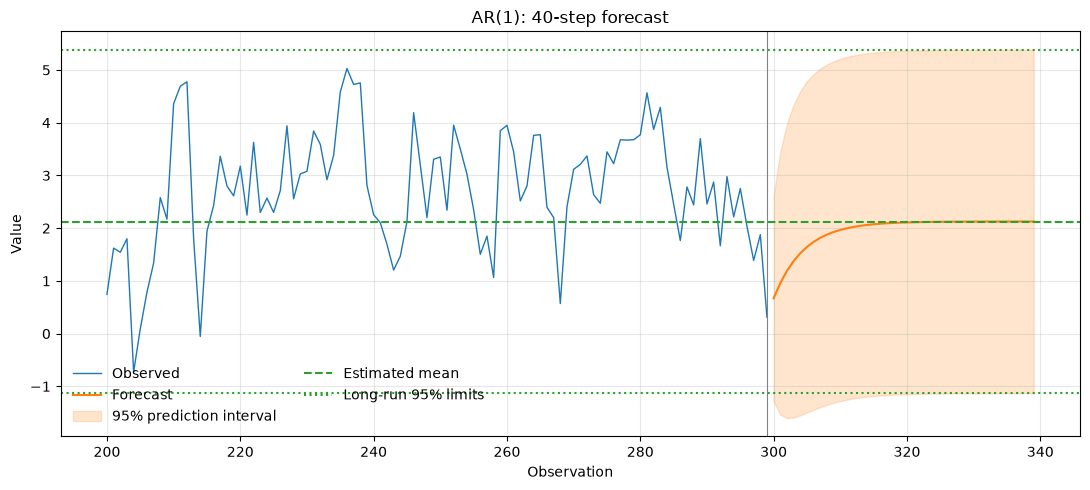

In [21]:
# Fit AR(1), forecast 40 steps, and compare the software output with the formulas.
fit_ar1_5a = ARIMA(ar1_sim, order=(1, 0, 0), trend='c').fit()
forecast_5a = fit_ar1_5a.get_forecast(40).summary_frame()
mu_5a = fit_ar1_5a.params['const']
phi_5a = fit_ar1_5a.params['ar.L1']
sigma2_5a = fit_ar1_5a.params['sigma2']
horizons_5a = np.array([1, 5, 10, 40])
last_5a = float(ar1_sim.iloc[-1])
formula_mean_5a = mu_5a + phi_5a ** horizons_5a * (last_5a - mu_5a)
formula_se_5a = np.sqrt(sigma2_5a * (1 - phi_5a ** (2 * horizons_5a)) / (1 - phi_5a ** 2))
comparison_5a = pd.DataFrame({
    'forecast (ARIMA)': forecast_5a['mean'].iloc[horizons_5a - 1].to_numpy(),
    'forecast (formula)': formula_mean_5a,
    'SE (ARIMA)': forecast_5a['mean_se'].iloc[horizons_5a - 1].to_numpy(),
    'SE (formula)': formula_se_5a,
}, index=pd.Index(horizons_5a, name='h'))
print(f'Estimated mu={mu_5a:.4f}, phi={phi_5a:.4f}, sigma^2={sigma2_5a:.4f}')
display(comparison_5a.round(4))

# Plot recent observations, forecasts, prediction interval, and long-run mean band.
forecast_index_5a = np.arange(len(ar1_sim), len(ar1_sim) + 40)
forecast_mean_5a = forecast_5a['mean'].to_numpy()
forecast_lower_5a = forecast_5a['mean_ci_lower'].to_numpy()
forecast_upper_5a = forecast_5a['mean_ci_upper'].to_numpy()
long_run_se_5a = np.sqrt(sigma2_5a / (1 - phi_5a ** 2))
fig, ax = plt.subplots(figsize=(11, 5))
recent_index_5a = np.arange(len(ar1_sim) - 100, len(ar1_sim))
ax.plot(recent_index_5a, ar1_sim.iloc[-100:], label='Observed', linewidth=1)
ax.plot(forecast_index_5a, forecast_mean_5a, color='tab:orange', label='Forecast')
ax.fill_between(forecast_index_5a, forecast_lower_5a, forecast_upper_5a,
                color='tab:orange', alpha=0.2, label='95% prediction interval')
ax.axhline(mu_5a, color='tab:green', linestyle='--', label='Estimated mean')
ax.axhline(mu_5a + 1.96 * long_run_se_5a, color='tab:green', linestyle=':', label='Long-run 95% limits')
ax.axhline(mu_5a - 1.96 * long_run_se_5a, color='tab:green', linestyle=':')
ax.axvline(len(ar1_sim) - 1, color='gray', linewidth=0.8)
ax.set(title='AR(1): 40-step forecast', xlabel='Observation', ylabel='Value')
ax.legend(ncol=2, frameon=False)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


**Task 5B.** Fit ARIMA(0, 1, 0) with `trend='t'` (a random walk with drift) to `log_price`, using `log_price.reset_index(drop=True)` so that the forecasts are indexed by day number. Report the estimated drift (`x1`) and $\sigma^2$, forecast 252 trading days ahead, and compare the standard errors at $h$ = 1, 21, 63 and 252 with $\hat\sigma\sqrt{h}$. Plot the last 500 days of the log price with the forecasts and the 95% interval.

Reference: the drift is 0.0317 and $\hat\sigma^2$ = 1.2938; the standard error at $h$ = 252 is 18.057.

Estimated drift=0.0317, sigma^2=1.2938


,SE (ARIMA),SE (sigma * sqrt(h))
h,,
1,1.1375,1.1375
21,5.2125,5.2125
63,9.0283,9.0283
252,18.0566,18.0566


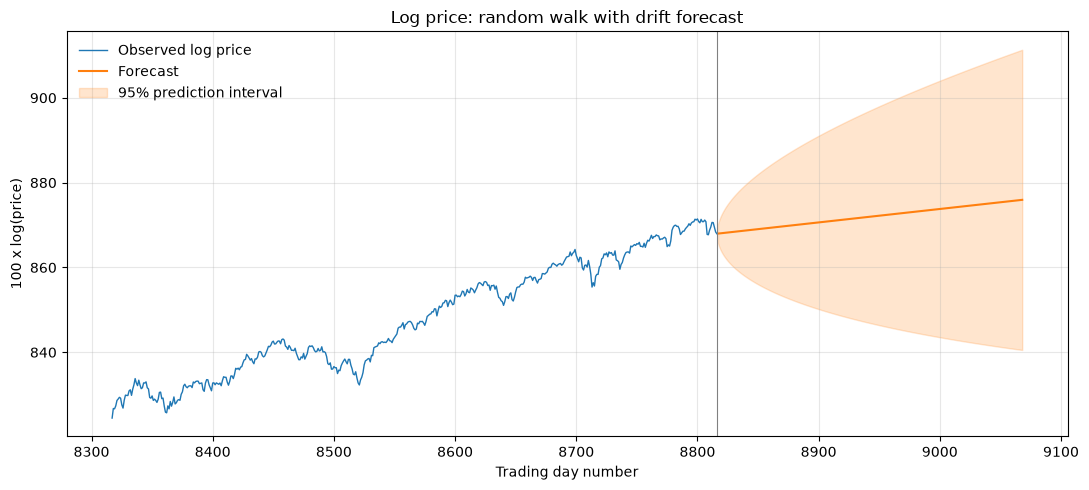

In [ ]:
# Fit a random walk with drift to log price (use a simple day-number index).
log_price_days_5b = log_price.reset_index(drop=True)
fit_rw_5b = ARIMA(log_price_days_5b, order=(0, 1, 0), trend='t').fit()#linear trend
forecast_5b = fit_rw_5b.get_forecast(252).summary_frame()
drift_5b = fit_rw_5b.params['x1']
sigma2_5b = fit_rw_5b.params['sigma2']
horizons_5b = np.array([1, 21, 63, 252])
formula_se_5b = np.sqrt(sigma2_5b * horizons_5b)
comparison_5b = pd.DataFrame({
    'SE (ARIMA)': forecast_5b['mean_se'].iloc[horizons_5b - 1].to_numpy(),
    'SE (sigma * sqrt(h))': formula_se_5b,
}, index=pd.Index(horizons_5b, name='h'))
print(f'Estimated drift={drift_5b:.4f}, sigma^2={sigma2_5b:.4f}')
display(comparison_5b.round(4))

# Plot the last 500 observations and 252-step forecast with its 95% interval.
forecast_index_5b = np.arange(len(log_price_days_5b), len(log_price_days_5b) + 252)
fig, ax = plt.subplots(figsize=(11, 5))
obs_index_5b = np.arange(len(log_price_days_5b) - 500, len(log_price_days_5b))
ax.plot(obs_index_5b, log_price_days_5b.iloc[-500:], label='Observed log price', linewidth=1)
ax.plot(forecast_index_5b, forecast_5b['mean'], color='tab:orange', label='Forecast')
ax.fill_between(forecast_index_5b, forecast_5b['mean_ci_lower'], forecast_5b['mean_ci_upper'],
                color='tab:orange', alpha=0.2, label='95% prediction interval')
ax.axvline(len(log_price_days_5b) - 1, color='gray', linewidth=0.8)
ax.set(title='Log price: random walk with drift forecast', xlabel='Trading day number', ylabel='100 x log(price)')
ax.legend(frameon=False)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


**Task 5C.**

1. Fit ARIMA(1, 0, 0) with `trend='c'` to the full `vix_m` and forecast 24 months ahead. Report the forecast and its standard error at $h$ = 1, 3, 6, 12 and 24, and plot the last 60 months with the forecasts, the 95% interval and the estimated mean.
2. Take the AR(1) fitted up to 2014 in Task 4D, with estimates $\hat\mu$ and $\hat\phi$. For every month from January 2015 on, forecast its VIX from the value $h$ months earlier with the formula $\hat\mu + \hat\phi^h (X_{t-h} - \hat\mu)$, and compare with the random-walk forecast $X_{t-h}$. Report the $R^2$ relative to the random walk for $h$ = 1, 3, 6 and 12.

Reference: the forecast is 16.402 at $h$ = 1 and 19.399 at $h$ = 24, with standard errors 3.901 and 7.439; the $R^2$ relative to the random walk is 0.0883 at $h$ = 1 and 0.4499 at $h$ = 12.

vix,forecast,standard error
h,,
1,16.402,3.901
3,17.247,5.853
6,18.100,6.879
12,18.951,7.362
24,19.399,7.439


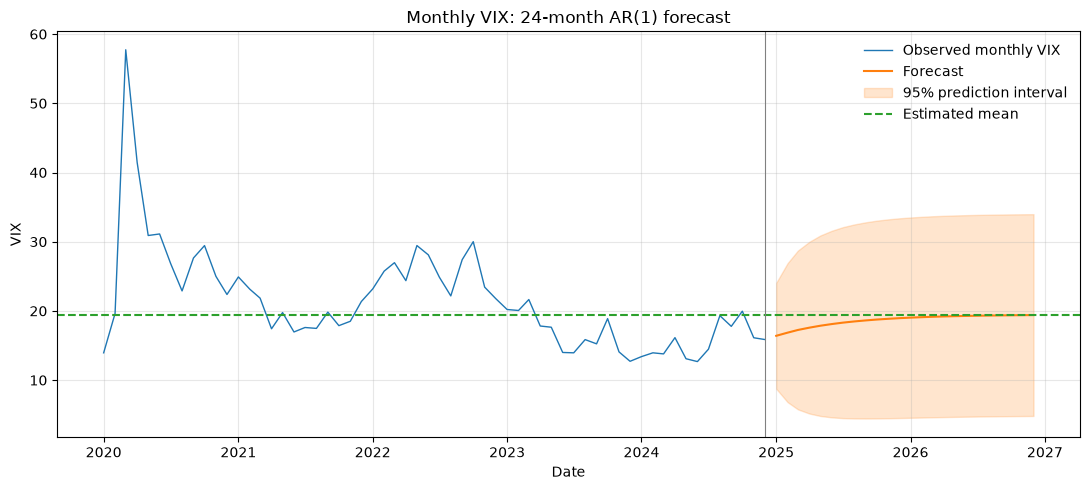

In [ ]:
#Fit AR(1) to the full monthly VIX series and forecast 24 months.
fit_ar1_vix_5c = ARIMA(vix_m, order=(1, 0, 0), trend='c').fit()
forecast_vix_5c = fit_ar1_vix_5c.get_forecast(24).summary_frame()
horizons_5c = np.array([1, 3, 6, 12, 24])
forecast_table_5c = forecast_vix_5c.iloc[horizons_5c - 1][['mean', 'mean_se']].copy()
forecast_table_5c.index = pd.Index(horizons_5c, name='h')
forecast_table_5c = forecast_table_5c.rename(columns={'mean': 'forecast', 'mean_se': 'standard error'})
display(forecast_table_5c.round(3))

mu_vix_5c = fit_ar1_vix_5c.params['const']
forecast_index_5c = pd.date_range(vix_m.index[-1] + pd.offsets.MonthBegin(1), periods=24, freq='MS')
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(vix_m.index[-60:], vix_m.iloc[-60:], label='Observed monthly VIX', linewidth=1)
ax.plot(forecast_index_5c, forecast_vix_5c['mean'].to_numpy(), color='tab:orange', label='Forecast')
ax.fill_between(forecast_index_5c, forecast_vix_5c['mean_ci_lower'].to_numpy(),
                forecast_vix_5c['mean_ci_upper'].to_numpy(), color='tab:orange', alpha=0.2,
                label='95% prediction interval')
ax.axhline(mu_vix_5c, color='tab:green', linestyle='--', label='Estimated mean')
ax.axvline(vix_m.index[-1], color='gray', linewidth=0.8)
ax.set(title='Monthly VIX: 24-month AR(1) forecast', xlabel='Date', ylabel='VIX')
ax.legend(frameon=False)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

**Question 5.1**

Using Tasks 5A, 5B and 5C, describe what happens to the forecast and to the width of the prediction interval as $h$ grows, for the AR(1) and for the random walk. Explain the difference using the formulas, and what it means for long-horizon forecasts of a stationary series and of a series with a unit root.

**Answer:**
The width of the prediction increase for both AR(1) and random walk as the variance increase. AR(1) increase by smaller amount. The $\mathrm{Var}(X_{n+h} - \hat X_{n+h})=\sigma^2\, \frac{1 - \phi^{2h}}{1 - \phi^2}$ so it only increases by $\sigma^2\phi^{2(h-1)}$. Random walk with a drift the variance increases by $\sigma^2 $ hence this is much larger. Series with a unit root(Random Walk case) has long run forecasts with larger width than stationary series given the same confidence interval. It can also be said that the former has forecast less reliable than the later.

**Question 5.2**

In Task 5C, why does the AR(1) gain more over the random walk as $h$ grows? Use the forecast formula and the half-life of the VIX.

**Answer:**
The AR(1) predicted formula is $\hat X_{n+h} = \mu + \phi^h (X_n - \mu)$ so it is pulled towards the mean as h grows. I am not sure about the half-life def here so I asked AI. It says it is the $\hat X-\hat\mu$ to be half. Then that is solving h for $\hat\phi^h=1/2$ which is around 5.77 month.

**Question 5.3**

The 95% interval in Task 5C is symmetric around the forecast, and its lower end falls below any monthly VIX in the data. Which assumption behind the interval does the VIX violate? Use the plot of `vix` in Task 1B.

**Answer:**
This is because ARIMA(1,0,0) with constant trend assume the data to be stationary. However, as shown by the graph, mean and variance in 1B, VIX ay not be stationary at all since its mean and varince is changing drastically overtime.
Also, the error is normally distributed hence it is symmetric, but VIX obviously don't follow such trend(upper error variance larger than downward error)

# 6. Volatility and GARCH

Sections 2 to 5 modelled the conditional **mean**, the best forecast of a series given its past. For the VIX there was a lot to find; for daily returns there was little (Section 2). Week 1 found that extreme days cluster in time, and Task 1B found that the standard deviation of returns differs across periods. This section models the conditional **variance**.

Write the return as

$$r_t = \mu + \varepsilon_t, \qquad \varepsilon_t = \sigma_t z_t,$$

where the $z_t$ are independent with mean 0 and variance 1, and $\sigma_t^2 = \mathrm{Var}(r_t \mid \text{past})$ is the conditional variance, which is known one day in advance.

- **ARCH(1)**: $\sigma_t^2 = \omega + \alpha\, \varepsilon_{t-1}^2$. A large shock yesterday, of either sign, raises today's variance.
- **GARCH(1, 1)**: $\sigma_t^2 = \omega + \alpha\, \varepsilon_{t-1}^2 + \beta\, \sigma_{t-1}^2$, with $\omega > 0$ and $\alpha, \beta \ge 0$. Today's variance combines a constant, yesterday's squared shock and yesterday's variance. Substituting repeatedly shows that $\sigma_t^2$ depends on all past squared shocks with weights $\alpha, \alpha\beta, \alpha\beta^2, \dots$, so one extra parameter gives the model a long memory.

Properties of GARCH(1, 1):

- **Uncorrelated shocks.** For $k \ge 1$, $\mathbb{E}[\varepsilon_t \varepsilon_{t-k}] = \mathbb{E}[\sigma_t \varepsilon_{t-k}]\, \mathbb{E}[z_t] = 0$, because $z_t$ is independent of everything before $t$. So $\varepsilon_t$ is white noise.
- **Persistence.** The variance forecast $h$ days ahead satisfies $\mathbb{E}[\sigma_{t+h}^2 \mid \text{past}] - \bar\sigma^2 = (\alpha + \beta)^{h-1} (\sigma_{t+1}^2 - \bar\sigma^2)$: the gap to the long-run level shrinks by the factor $\alpha + \beta$ each day. $\alpha + \beta$ is called the persistence, and $\ln 0.5 / \ln(\alpha + \beta)$ is the half-life of a volatility shock.
- **Unconditional variance.** If $\alpha + \beta < 1$, the variance of $\varepsilon_t$ is the same on every day, $\bar\sigma^2 = \omega / (1 - \alpha - \beta)$, even though the conditional variance $\sigma_t^2$ changes every day.

In `arch`, `arch_model(y, mean='Constant', vol='GARCH', p=1, q=1, dist='normal').fit(disp='off')` estimates a GARCH(1, 1) with normal $z_t$ by maximum likelihood, and `vol='ARCH', p=1` gives an ARCH(1). The result has `.params` (`mu`, `omega`, `alpha[1]`, `beta[1]`), `.aic`, `.conditional_volatility` ($\hat\sigma_t$), `.std_resid` ($\hat z_t = \hat\varepsilon_t / \hat\sigma_t$) and `.forecast(...)`. The optimizer works best when returns are of order 1, which is why `r` is in percent; the estimates of $\omega$ depend on that scale.

**Task 6A.** For the log return `r`, compute the sample ACF at lags 1 to 20 of $r_t$, $|r_t|$ and $r_t^2$. Plot the three correlograms side by side with `plot_correlogram`, and report $\hat\rho_1$ and $Q(10)$ for each.

Reference: $\hat\rho_1$ is -0.079 for $r_t$, 0.276 for $|r_t|$ and 0.316 for $r_t^2$; $Q(10)$ is 90.9, 8255.6 and 8153.1.

,rho_1,Q(10),p-value
series,,,
r,-0.0786,90.9481,0.0
|r|,0.2755,8255.6119,0.0
r^2,0.3157,8153.1204,0.0


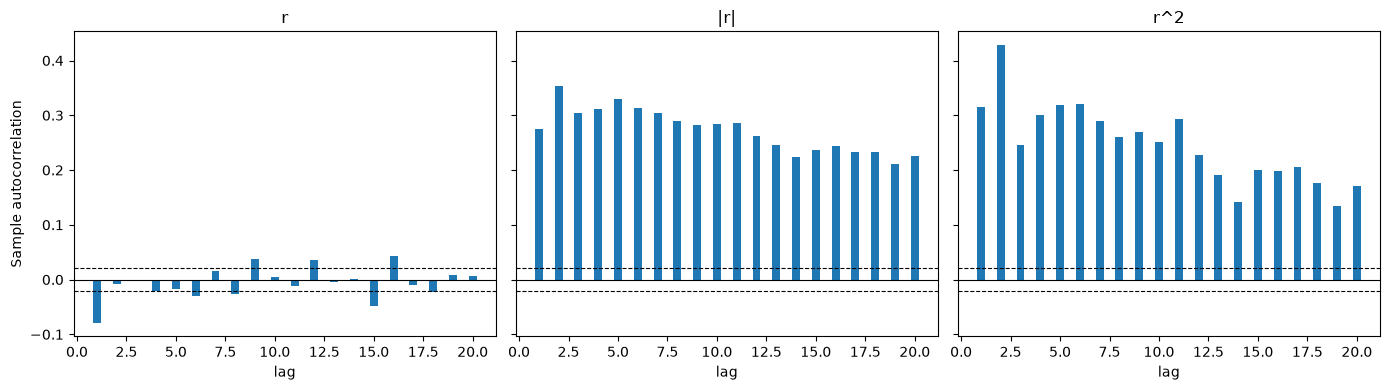

In [ ]:
# ACFs and Ljung-Box summaries for returns, absolute returns, and squared returns.
series_6a = {
    'r': r,
    '|r|': r.abs(),
    'r^2': r ** 2,
}
acf_results_6a = {}
summary_rows_6a = []
for name, series in series_6a.items():
    values = series.dropna().to_numpy(dtype=float)
    acf_values = np.array([ACF(values, lag) for lag in range(1, 21)])
    lb = acorr_ljungbox(values, lags=[10], return_df=True)
    acf_results_6a[name] = (acf_values, len(values))
    summary_rows_6a.append({
        'series': name,
        'rho_1': acf_values[0],
        'Q(10)': lb['lb_stat'].iloc[0],
        'p-value': lb['lb_pvalue'].iloc[0],
    })

summary_6a = pd.DataFrame(summary_rows_6a).set_index('series')
display(summary_6a.round(4))

fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (name, (acf_values, n)) in zip(axs, acf_results_6a.items()):
    plot_correlogram(acf_values, n, ax, name)
axs[0].set_ylabel('Sample autocorrelation')
fig.tight_layout()
plt.show()


**Task 6B.** Fit an ARCH(1) and a GARCH(1, 1) to the log return `r` and report the estimates and the AIC of each. For the GARCH(1, 1), also report the persistence $\alpha + \beta$, the half-life, and the unconditional standard deviation $\sqrt{\bar\sigma^2}$ against the sample standard deviation of $r_t$. Plot $\hat\sigma_t$ together with $|r_t|$.

Reference: GARCH(1, 1) has $\hat\alpha$ = 0.1035, $\hat\beta$ = 0.8812 and AIC 23437.56, against 26069.66 for ARCH(1); the half-life is 44.8 days.

Parameter estimates and AIC:


,ARCH(1),"GARCH(1,1)"
alpha[1],0.3662,0.1035
beta[1],NaN,0.8812
mu,0.0565,0.0605
omega,0.8468,0.0186


ARCH(1) AIC       26069.66
GARCH(1,1) AIC    23437.56
dtype: float64
GARCH(1,1) volatility summary:


persistence (alpha + beta)     0.9847
half-life (days)              44.8382
unconditional SD               1.0997
sample SD of returns           1.1376
dtype: float64

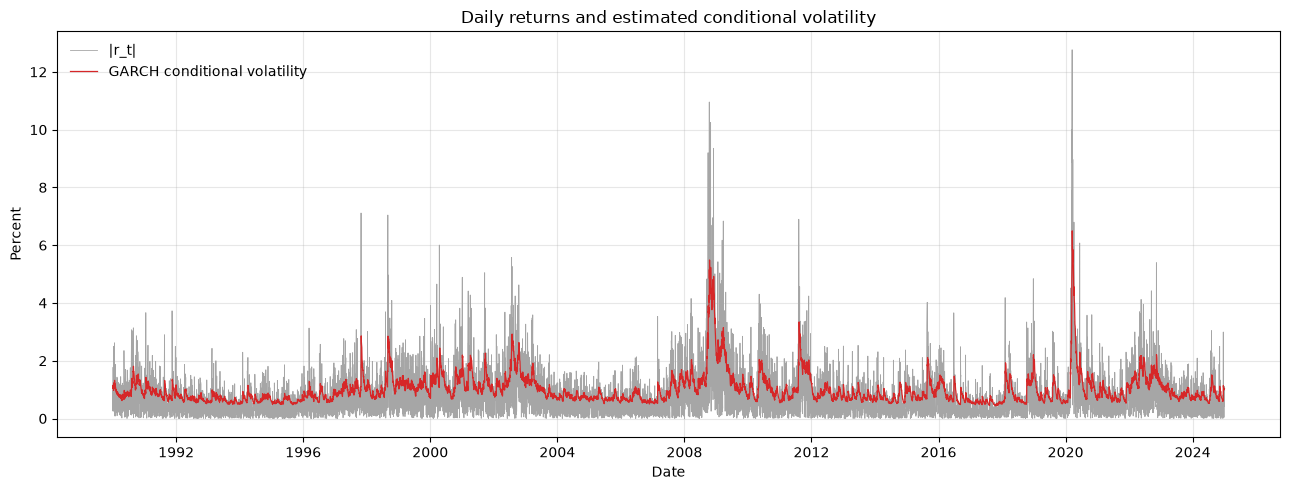

In [ ]:
# Fit ARCH(1) and GARCH(1, 1) models to daily log returns (in percent).
arch_fit_6b = arch_model(r, mean='Constant', vol='ARCH', p=1, dist='normal').fit(disp='off')
garch_fit_6b = arch_model(r, mean='Constant', vol='GARCH', p=1, q=1, dist='normal').fit(disp='off')

estimates_6b = pd.DataFrame({
    'ARCH(1)': arch_fit_6b.params,
    'GARCH(1,1)': garch_fit_6b.params,
})
print('Parameter estimates and AIC:')
display(estimates_6b.round(4))
print(pd.Series({'ARCH(1) AIC': arch_fit_6b.aic, 'GARCH(1,1) AIC': garch_fit_6b.aic}).round(2))

alpha_6b = garch_fit_6b.params['alpha[1]']
beta_6b = garch_fit_6b.params['beta[1]']
omega_6b = garch_fit_6b.params['omega']
persistence_6b = alpha_6b + beta_6b
half_life_6b = np.log(0.5) / np.log(persistence_6b)
unconditional_sd_6b = np.sqrt(omega_6b / (1 - persistence_6b)) if persistence_6b < 1 else np.nan
summary_6b = pd.Series({
    'persistence (alpha + beta)': persistence_6b,
    'half-life (days)': half_life_6b,
    'unconditional SD': unconditional_sd_6b,
    'sample SD of returns': r.std(),
})
print('GARCH(1,1) volatility summary:')
display(summary_6b.round(4))

# Plot conditional volatility with absolute returns on the same daily index.
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(r.index, np.abs(r), color='0.65', linewidth=0.6, label='|r_t|')
ax.plot(r.index, garch_fit_6b.conditional_volatility, color='tab:red', linewidth=0.9,
        label='GARCH conditional volatility')
ax.set(title='Daily returns and estimated conditional volatility', xlabel='Date', ylabel='Percent')
ax.legend(frameon=False)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()


In [ ]:
# Diagnose standardized residuals from the fitted GARCH(1, 1).
std_resid_6c = pd.Series(garch_fit_6b.std_resid, index=r.index).dropna()
std_resid_sq_6c = std_resid_6c ** 2

lb_std_6c = acorr_ljungbox(std_resid_6c, lags=[10], return_df=True)
lb_std_sq_6c = acorr_ljungbox(std_resid_sq_6c, lags=[10], return_df=True)
summary_6c = pd.DataFrame({
    'Q(10)': [lb_std_6c['lb_stat'].iloc[0], lb_std_sq_6c['lb_stat'].iloc[0]],
    'p-value': [lb_std_6c['lb_pvalue'].iloc[0], lb_std_sq_6c['lb_pvalue'].iloc[0]],
}, index=['Standardized residuals', 'Squared standardized residuals'])
display(summary_6c.round(4))

kurtosis_6c = pd.Series({
    'Returns r': r.kurt(),
    'Standardized residuals z': std_resid_6c.kurt(),
}, name='Excess kurtosis')
display(kurtosis_6c.round(4))


,Q(10),p-value
Standardized residuals,20.6197,0.0239
Squared standardized residuals,14.7746,0.1405


Returns r                   10.6691
Standardized residuals z     1.9212
Name: Excess kurtosis, dtype: float64

**Task 6D.** Use the fitted GARCH(1, 1) to forecast the conditional volatility $\sqrt{\mathbb{E}[\sigma_{t+h}^2 \mid \text{past}]}$ for $h = 1, \dots, 60$ from two dates: the end of the sample, with `garch.forecast(horizon=60, reindex=False)`, and 2020-03-16, with `garch.forecast(horizon=60, start='2020-03-16', reindex=False)`. In each case the forecasts made on the first date are in the first row of `.variance`. Report both at $h$ = 1, 10 and 60, and plot them against $h$ together with the unconditional standard deviation.

Reference: from 2020-03-16 the forecast is 6.496 at $h$ = 1 and 4.204 at $h$ = 60; from the end of the sample it is 0.985 at $h$ = 1.

,From sample end,From 2020-03-16
horizon,,
1,0.985,6.496
10,1.001,6.072
60,1.055,4.204


Unconditional standard deviation: 1.100


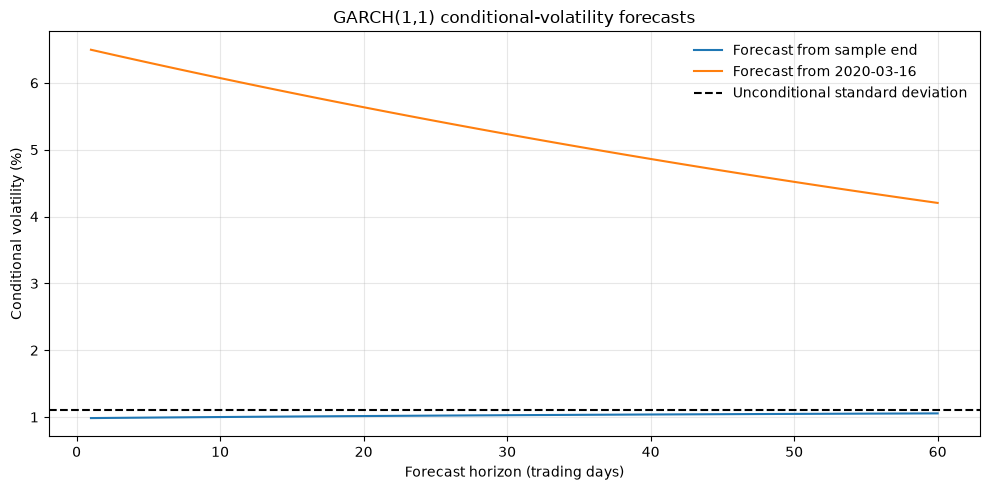

In [ ]:
# Forecast GARCH conditional variance 60 days ahead from two forecast origins.
forecast_end_6d = garch_fit_6b.forecast(horizon=60, reindex=False)
forecast_crash_6d = garch_fit_6b.forecast(
    horizon=60, start='2020-03-16', reindex=False
)

# Convert the first forecast row from variance to conditional volatility.
vol_end_6d = np.sqrt(forecast_end_6d.variance.iloc[0].to_numpy())
vol_crash_6d = np.sqrt(forecast_crash_6d.variance.iloc[0].to_numpy())
horizons_6d = np.array([1, 10, 60])
forecast_table_6d = pd.DataFrame({
    'From sample end': vol_end_6d[horizons_6d - 1],
    'From 2020-03-16': vol_crash_6d[horizons_6d - 1],
}, index=pd.Index(horizons_6d, name='horizon'))
display(forecast_table_6d.round(3))

# Long-run unconditional standard deviation under alpha + beta < 1.
alpha_6d = garch_fit_6b.params['alpha[1]']
beta_6d = garch_fit_6b.params['beta[1]']
omega_6d = garch_fit_6b.params['omega']
persistence_6d = alpha_6d + beta_6d
unconditional_sd_6d = np.sqrt(omega_6d / (1 - persistence_6d))
print(f'Unconditional standard deviation: {unconditional_sd_6d:.3f}')

# Plot forecast volatility by horizon for both origins.
days_6d = np.arange(1, 61)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(days_6d, vol_end_6d, label='Forecast from sample end')
ax.plot(days_6d, vol_crash_6d, label='Forecast from 2020-03-16')
ax.axhline(unconditional_sd_6d, color='black', linestyle='--',
           label='Unconditional standard deviation')
ax.set(title='GARCH(1,1) conditional-volatility forecasts',
       xlabel='Forecast horizon (trading days)', ylabel='Conditional volatility (%)')
ax.grid(True, alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

Section 2 found a lag-1 autocorrelation of -0.0786 in the log return. $\hat\rho_1$ is close to the OLS slope of $r_t$ on $r_{t-1}$, so its significance can also be checked with the regression tools of Week 1.

**Task 6E.**

1. Regress `r` on its own value the day before. Report the slope and its t-statistic with classical standard errors and with HC1 standard errors.
2. Report $\hat\rho_1$ and $Q(10)$ with its p-value for the GARCH standardized residuals $\hat z_t$.
3. Report the lag-1 sample autocorrelation of `r` in each five-year period 1990–1994, 1995–1999, ..., 2020–2024.

Reference: the slope is -0.0786, with a t-statistic of -7.40 (classical) and -3.49 (HC1); $\hat\rho_1$ of $\hat z_t$ is -0.010 and its $Q(10)$ is 20.62 (p = 0.0239); the lag-1 autocorrelation of `r` is -0.179 in 2020–2024.

In [30]:
# 1. Regress today's return on yesterday's return, with classical and HC1 errors.
r_values_6e = r.dropna()
y_6e = r_values_6e.iloc[1:].to_numpy()
x_lag_6e = r_values_6e.iloc[:-1].to_numpy()
X_6e = sm.add_constant(x_lag_6e)
ols_6e = sm.OLS(y_6e, X_6e).fit()
ols_hc1_6e = ols_6e.get_robustcov_results(cov_type='HC1')
regression_summary_6e = pd.DataFrame({
    'slope': [ols_6e.params[1], ols_hc1_6e.params[1]],
    't-statistic': [ols_6e.tvalues[1], ols_hc1_6e.tvalues[1]],
}, index=['Classical standard errors', 'HC1 standard errors'])
display(regression_summary_6e.round(4))

# 2. Lag-1 autocorrelation and Ljung-Box test for standardized GARCH residuals.
std_resid_6e = pd.Series(garch_fit_6b.std_resid, index=r.index).dropna()
lb_std_6e = acorr_ljungbox(std_resid_6e, lags=[10], return_df=True)
residual_summary_6e = pd.Series({
    'rho_1': ACF(std_resid_6e.to_numpy(), 1),
    'Q(10)': lb_std_6e['lb_stat'].iloc[0],
    'Q(10) p-value': lb_std_6e['lb_pvalue'].iloc[0],
})
display(residual_summary_6e.round(4))

# 3. Lag-1 return autocorrelation in successive five-year periods.
period_rows_6e = []
for start_year in range(1990, 2025, 5):
    end_year = min(start_year + 4, 2024)
    period = r.loc[f'{start_year}-01-01':f'{end_year}-12-31'].dropna()
    period_rows_6e.append({
        'period': f'{start_year}-{end_year}',
        'n': len(period),
        'rho_1': ACF(period.to_numpy(), 1),
    })
period_acf_6e = pd.DataFrame(period_rows_6e).set_index('period')
display(period_acf_6e.round(4))


,slope,t-statistic
Classical standard errors,-0.0786,-7.4021
HC1 standard errors,-0.0786,-3.4858


rho_1            -0.0099
Q(10)            20.6197
Q(10) p-value     0.0239
dtype: float64

,n,rho_1
period,,
1990-1994,1265,0.0494
1995-1999,1263,-0.0038
2000-2004,1256,-0.0203
2005-2009,1259,-0.1326
2010-2014,1258,-0.0635
2015-2019,1258,-0.0213
2020-2024,1258,-0.1794


**Question 6.1**

Section 1 defined white noise as uncorrelated, not independent. Using Task 6A, explain how the log return can have little autocorrelation and yet not be independent over time. What feature of the data does the ACF of $r_t^2$ capture?

**Answer:**
Uncorrelated is only suggesting no linear relationship. Simple example is $X=Y^2$ which is uncorrelated but dependent. As for log return, they are not independent since return today and return tomorrow all depends on today's close. ACF of $r_t^2$ capture the share of $(\log P_{t-1})^2$ which is cancel out in the ACF for $r_t$

**Question 6.2**

Interpret $\alpha + \beta$ and the half-life from Task 6B using the two forecast paths in Task 6D. The variance forecast follows the same rule as the AR(1) forecast in Section 5: what plays the role of $\phi$, and what plays the role of $\mu$?

**Answer:**
The gap between last day $\sigma_t^2$ and $\bar\sigma^2$ shrinks by the factor $(\alpha+\beta)$ each day. Half life measure how long it takes to close half of the gap. In 2020-03-16, due to Covid, the volatility is high and such high volatility persist but moves towards the $\bar\sigma$. Similar to AR(1), $\mu$ is the $\sigma^2$ and $\phi$ is $(\alpha+\beta)$

**Question 6.3**

The return's standard deviation clearly differed across the periods of Task 1B, and $\hat\sigma_t$ in Task 6B moves from below 0.5 to above 6. Explain how a GARCH(1, 1) with $\alpha + \beta < 1$ can nonetheless be stationary, distinguishing the conditional from the unconditional variance.

**Answer:**
The conditional variance is given by GARCH and update when new data comes. However, the unconditional variance is just $\frac{\omega}{1-\alpha-\beta}$ so it is clearly constant for every $r_t$. The main difference is that current risk is changing but its long-run average is constant. So it is nonetheless stationary.

**Question 6.4**

Return to Question 2.2. The Ljung-Box test and the band $\pm 1.96/\sqrt{n}$ assume independent observations with constant variance. Using Tasks 6C and 6E, explain why volatility clustering makes these tools overstate the evidence for autocorrelation in returns, and say what you now conclude about the lag-1 autocorrelation of the S&P 500.

**Answer:**
Extreme days tends to cluster together and assuming constant variance ignore this fact. Imagine the returns goes down and bounce back largely. Such test will interpret the similar level of movement as a strong signal for correlation but in fact it is only because volatility clustering. As shown by 6E, the t-statistic is more close to 0 after accouting for changing volatility. This suggests that there is weaker evident for $\rho_1$ to not be 0. In fact, if we look at how it change across time, we will found it very unstable. Hence, I would conclude there is very weak lag1 autocorrelation. I did not say no because tasks 6C shows that the residual still have p-value >0.05 so there may still be some autocorrelation that is not caused by volatility clusting.
